# ВШЭ 2026: Математические методы анализа данных

## Семинар 9: Кластеризация

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn import datasets
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

# Содержание

- [Постановка задачи кластеризации](#task)
- [k-Means](#k-means)
- [Метрики качества кластеризации](#metrics)
- [DBSCAN](#dbscan)
- [Иерархическая кластеризация](#hierarchical)

## Постановка задачи кластеризации <a id="task"></a>

Дана выборка объектов $X = \{x_1, \dots, x_N\}$, $x_i \in \mathbb{R}^D$, **без меток**, и функция расстояния $\rho(x_i, x_j)$ (чаще всего евклидова).

Нужно построить отображение $a: X \to \{1, \dots, K\}$, которое каждому объекту ставит в соответствие номер кластера, так, чтобы:
- объекты **внутри** одного кластера были близки друг к другу;
- объекты из **разных** кластеров были далеки друг от друга.

Это задача обучения **без учителя**, и она поставлена нестрого:
- «близость» и «хорошее разбиение» можно формализовать по-разному — каждый алгоритм делает это по-своему;
- число кластеров $K$ часто заранее неизвестно;
- правильного ответа для проверки обычно нет.

Поэтому ниже мы посмотрим на три алгоритма с разной идеей «что такое кластер»:

| Алгоритм | Что считается кластером | Нужно ли задавать $K$ |
|---|---|---|
| k-Means | облако точек вокруг центра | да |
| DBSCAN | область высокой плотности | нет (задаём плотность) |
| Иерархическая | ветка дерева последовательных объединений | можно выбрать после обучения |

## Игрушечные данные <a id="toy"></a>

Сгенерируем три двумерных датасета разной формы: три «облака» (blobs), два вложенных кольца (circles) и два полумесяца (moons). На них хорошо видно, где какой алгоритм работает.

In [ ]:
n_samples = 1500
random_state = 170

X_blobs, y_blobs = datasets.make_blobs(centers=3, n_samples=n_samples, random_state=random_state, center_box=(-10, 10))
X_circles, y_circles = datasets.make_circles(n_samples=n_samples, factor=.5, noise=.05)
X_moons, y_moons = datasets.make_moons(n_samples=n_samples, noise=.05)

In [ ]:
X_blobs[:5], X_circles[:5], X_moons[:5]

(array([[ -5.19811282,   0.64186932],
        [ -5.75229538,   0.41862711],
        [-10.84489837,  -7.55352273],
        [ -4.57098483,  -0.80101741],
        [ -3.51916215,   0.0393449 ]]),
 array([[-0.50202312,  0.04905579],
        [ 0.47336916, -0.06286722],
        [ 0.11367086, -0.92977708],
        [-0.13452262,  0.95119677],
        [-0.26918503,  0.28044694]]),
 array([[ 0.23432623, -0.25981178],
        [ 0.49094647,  0.89904177],
        [-0.64136527,  0.7820985 ],
        [ 0.37348653, -0.2855094 ],
        [ 0.18028671, -0.01985476]]))

In [ ]:
y_blobs[:10]

array([1, 1, 0, 1, 1, 2, 0, 0, 0, 2])

In [ ]:
def plot_clusters(X, y):
    # Рисует точки; если переданы метки y — раскрашивает по кластерам

    if y is not None:
        for cluster_label in np.unique(y):
            # Нарисовать все объекты с меткой cluster_label
            plt.scatter(X[y == cluster_label, 0],     # 1-й признак объектов этого кластера
                        X[y == cluster_label, 1],     # 2-й признак объектов этого кластера
                        label=str(cluster_label))     # метка для легенды
    else:
        plt.scatter(X[:, 0], X[:, 1], label='объекты')

    plt.xlabel('X1', size=12)
    plt.ylabel('X2', size=12)
    plt.xticks(size=12)
    plt.yticks(size=12)

    plt.legend(loc='best', fontsize=12)
    plt.grid()
    plt.show()

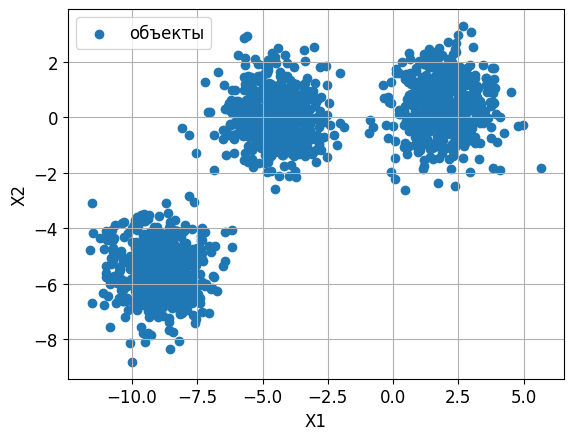

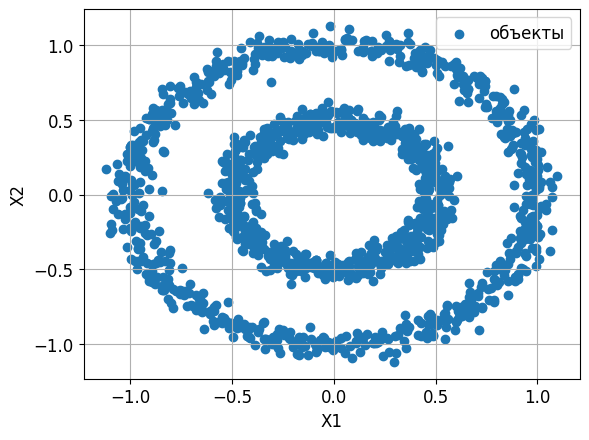

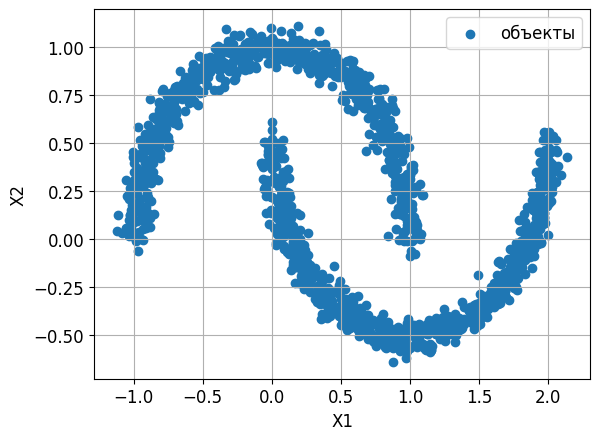

In [ ]:
plot_clusters(X_blobs, y=None)
plot_clusters(X_circles, y=None)
plot_clusters(X_moons, y=None)

## k-Means <a id="k-means"></a>

Алгоритм k-средних — простой и элегантный подход для разбиения набора данных на $K$ различных непересекающихся кластеров. Для выполнения кластеризации методом k-средних необходимо сначала задать желаемое число кластеров $K$; затем алгоритм отнесёт каждое наблюдение ровно к одному из $K$ кластеров.


Введём некоторые обозначения. Пусть $C_1, ..., C_K$ — множества, содержащие индексы наблюдений каждого кластера. Эти множества удовлетворяют двум свойствам:
1. Каждое наблюдение принадлежит хотя бы одному из $K$ кластеров.
2. Кластеры не пересекаются: ни одно наблюдение не принадлежит более чем одному кластеру.


Идея алгоритма k-средних состоит в том, что хорошая кластеризация — это та, при которой внутрикластерная дисперсия минимальна. Внутрикластерная дисперсия для кластера $C_k$ — это мера $W(C_k)$, показывающая, насколько наблюдения внутри кластера отличаются друг от друга. Таким образом, мы хотим решить задачу $$\sum_{k=1}^K W(C_k) \to \min_{C_k}.$$ Иными словами, требуется разбить наблюдения на $K$ кластеров так, чтобы суммарная внутрикластерная дисперсия, суммированная по всем $K$ кластерам, была минимальной.

Чтобы сделать это операционным, необходимо определить внутрикластерную дисперсию. Существует много способов её определить, однако наиболее распространённым является квадратичное евклидово расстояние. А именно, определим $$W(C_k) = \frac{1}{|C_k|}\sum_{i,i'\in C_k}\sum_{j=1}^p\left(x_{ij}-x_{i'j}\right)^2.$$ Иными словами, внутрикластерная дисперсия для $k$-го кластера — это сумма всех попарных квадратичных евклидовых расстояний между наблюдениями в $k$-м кластере, делённая на общее число наблюдений в этом кластере.


**Алгоритм** (итеративно уменьшает эту сумму):
1. Случайно выбрать $K$ начальных центров кластеров.
2. Отнести каждый объект к ближайшему центру.
3. Пересчитать центры как средние объектов своего кластера.
4. Повторять шаги 2–3, пока разбиение не перестанет меняться.

Результат зависит от начальных центров, поэтому алгоритм запускают несколько раз (`n_init`) и берут лучший вариант.

### k-Means на облаках

In [ ]:
#реализация k-Means из sklearn
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, max_iter=20, n_init=10)
kmeans.fit(X_blobs)
y_pred_blobs = kmeans.predict(X_blobs)

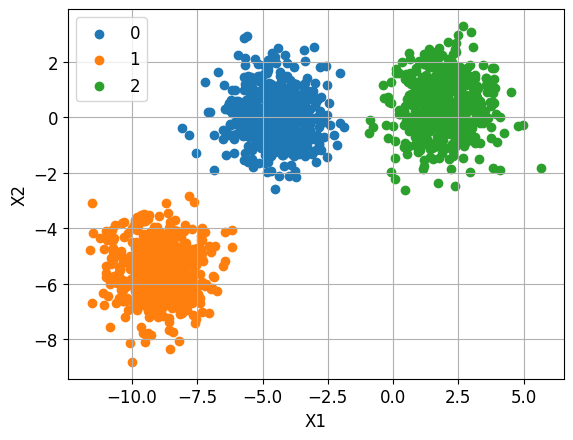

In [ ]:
plot_clusters(X_blobs, y_pred_blobs)

### k-Means на кольцах и полумесяцах

In [ ]:
kmeans = KMeans(n_clusters=2, max_iter=20, n_init=10)
kmeans.fit(X_circles)
y_pred_circles = kmeans.predict(X_circles)

kmeans = KMeans(n_clusters=2, max_iter=20, n_init=10)
kmeans.fit(X_moons)
y_pred_moons = kmeans.predict(X_moons)

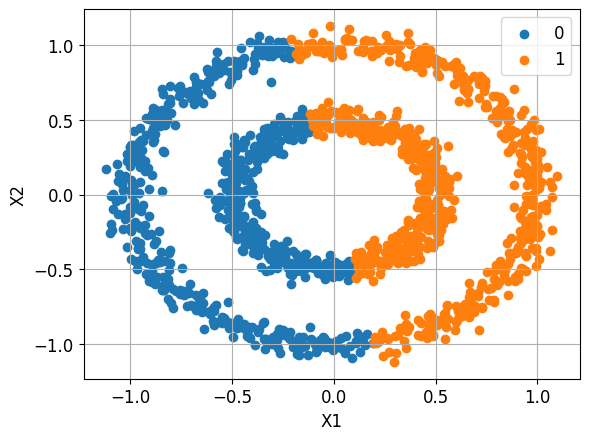

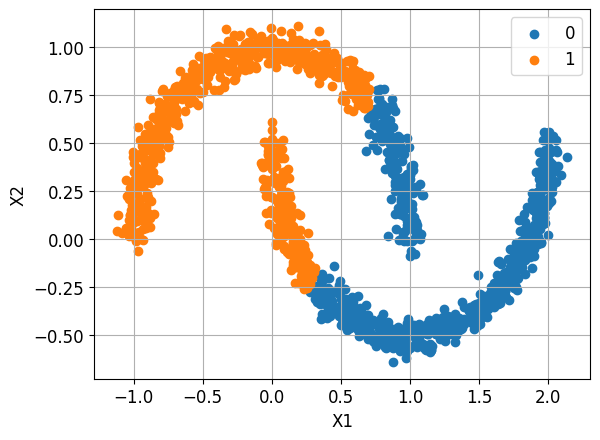

In [ ]:
plot_clusters(X_circles, y_pred_circles)
plot_clusters(X_moons, y_pred_moons)

k-Means плохо работает в этих примерах: он всегда делит пространство на выпуклые области вокруг центров (диаграмма Вороного), поэтому кольца и полумесяцы он разделить не может. Нужен алгоритм с другим понятием кластера — например, DBSCAN.

Но сначала ответим на вопрос, который возникает уже для k-Means: **как выбрать $K$ и как понять, что кластеризация получилась хорошей?**

## Метрики качества кластеризации <a id="metrics"></a>

Метрики делятся на два типа:
- **внутренние** — используют только сами данные и полученные метки (истинные метки не нужны). Их можно применять на практике;
- **внешние** — сравнивают кластеризацию с истинным разбиением. Годятся только когда разметка известна, например на игрушечных данных.

**Коэффициент силуэта (Silhouette Score)** — внутренняя метрика:

$$
s = \frac{b - a}{\max(a, b)}
$$

- $a$ — среднее расстояние от объекта до остальных точек его кластера;
- $b$ — среднее расстояние от объекта до точек ближайшего соседнего кластера.

$s \in [-1, 1]$: близко к 1 — объект хорошо попал в свой кластер, около 0 — на границе кластеров, меньше 0 — скорее относится к соседнему кластеру. Силуэт всего разбиения — среднее по всем объектам.

**Скорректированный индекс Рэнда (Adjusted Rand Index, ARI)** — внешняя метрика. Рассмотрим все пары объектов и сравним предсказанное разбиение $X$ с истинным $Y$:

$$
RI = \frac{a + b}{a + b + c + d}, \qquad ARI = \frac{RI - \mathbb{E}[RI]}{\max(RI) - \mathbb{E}[RI]}
$$

- $a$ — пары, которые в одном кластере и в $X$, и в $Y$;
- $b$ — пары, которые в разных кластерах и в $X$, и в $Y$;
- $c$ — пары, которые в одном кластере в $X$, но в разных в $Y$;
- $d$ — пары, которые в разных кластерах в $X$, но в одном в $Y$.

$RI$ — доля пар, на которых разбиения согласны. $ARI$ поправляет её на случайное совпадение: $ARI \approx 0$ для случайного разбиения, $ARI = 1$ при полном совпадении.

Посчитаем обе метрики для k-Means на облаках при разном числе кластеров.

In [ ]:
silhouette_score_values = []
adjusted_rand_score_values = []
n_clusters = np.arange(2, 21)

for n in n_clusters:
    clusterer = KMeans(n_clusters=n, max_iter=10, n_init=10)
    y_pred = clusterer.fit_predict(X_blobs)

    silhouette_score_values.append(silhouette_score(X_blobs, y_pred))       # не использует истинные метки
    adjusted_rand_score_values.append(adjusted_rand_score(y_blobs, y_pred)) # сравнивает с истинными метками

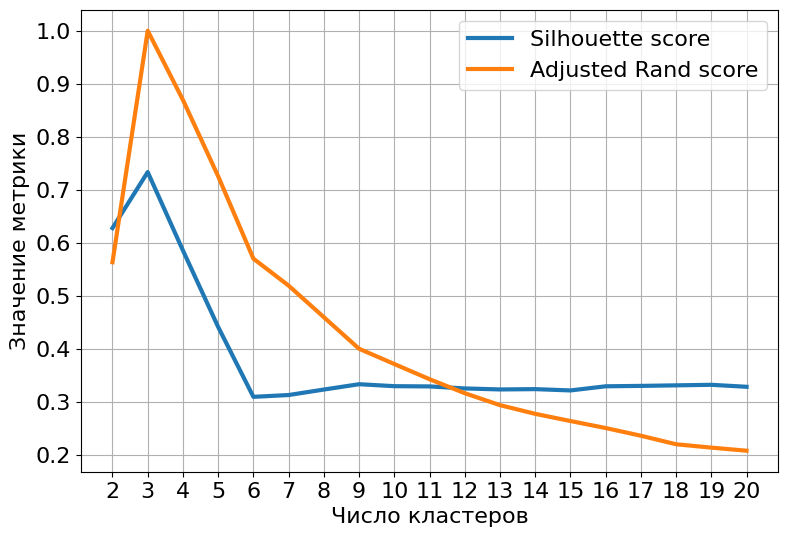

In [ ]:
plt.figure(figsize=(9, 6))
plt.plot(n_clusters, silhouette_score_values, linewidth=3, label='Silhouette score')
plt.plot(n_clusters, adjusted_rand_score_values, linewidth=3, label='Adjusted Rand score')
plt.xlabel('Число кластеров', size=16)
plt.ylabel('Значение метрики', size=16)
plt.xticks(n_clusters, size=16)
plt.yticks(size=16)
plt.legend(loc='best', fontsize=16)
plt.show()

Обе метрики достигают максимума при 3 кластерах — столько облаков мы и генерировали. Важно, что силуэт нашёл правильный ответ **без истинных меток**, поэтому на практике для выбора числа кластеров используют именно внутренние метрики. Дальше мы будем применять силуэт для подбора параметров DBSCAN и иерархической кластеризации.

## DBSCAN <a id="dbscan"></a>

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) считает кластером область, где точки расположены **плотно**. Параметры:
- `eps` — радиус окрестности точки;
- `min_samples` — сколько точек должно быть в окрестности, чтобы она считалась плотной.

Точки бывают трёх типов:
- **основные** (core) — в их `eps`-окрестности не меньше `min_samples` точек;
- **граничные** — сами не основные, но лежат в окрестности основной точки;
- **шум (выбросы)** — все остальные; им присваивается метка **`-1`**.

Алгоритм:
1. Выбрать случайную непосещённую точку и найти её соседей в радиусе `eps`.
2. Если соседей меньше `min_samples` — пометить точку как шум (позже она может оказаться граничной).
3. Если нет — начать новый кластер и рекурсивно добавлять в него всех соседей основных точек.
4. Когда кластер перестал расти — выбрать новую непосещённую точку и повторить.

Особенности:
- число кластеров не задаётся — оно получается само;
- кластеры могут быть любой формы;
- выбросы выделяются автоматически (связь с темой аномалий!).

Красивая визуализация DBSCAN — [здесь](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/).

### DBSCAN на облаках: параметры по умолчанию

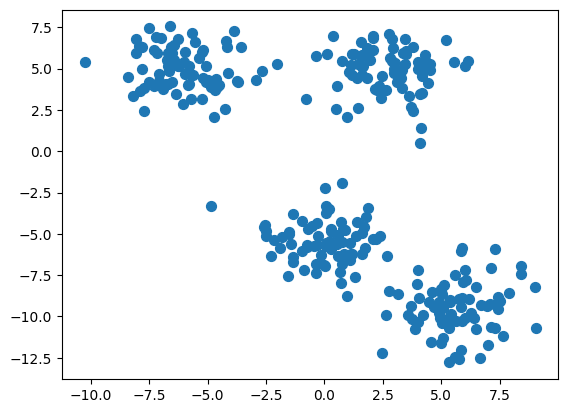

In [ ]:
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=1.5, random_state=10)
plt.scatter(X[:, 0], X[:, 1], s=50);

In [ ]:
dbscan = DBSCAN().fit(X)
labels = dbscan.labels_
labels

array([-1,  0,  1, -1, -1,  2, -1,  3, -1, -1,  3, -1, -1, -1, -1, -1,  3,
        5, -1, -1, -1, -1,  6, -1, -1,  4, -1,  5,  9,  5,  6, -1, -1, -1,
       -1,  1,  6, -1, -1, -1,  6, -1,  7,  8, -1, -1, -1, -1,  0,  7,  6,
       -1, -1,  3,  2, -1, 10, -1, -1, -1,  6, -1,  2, -1, -1,  3,  4, -1,
       -1,  4, -1, -1,  2, -1,  5, -1,  2,  7, -1, -1, -1,  1, -1,  3, -1,
       -1,  2, -1, -1, -1,  4, -1, -1,  2, -1, -1, -1, -1, -1,  3,  3,  4,
        1, -1, -1, 12, -1,  6, -1,  3, -1, -1,  5, -1,  0, -1, 10, -1,  9,
       -1, -1, -1,  6, -1,  8,  3, -1,  1, -1, -1,  3, -1,  4, -1, -1,  3,
       -1, -1, 10,  9, -1, -1, -1,  6, -1, -1, -1,  0, -1,  3, -1, -1, 10,
        6, -1,  4, -1, -1,  3, -1,  2, -1, 10, 11, -1, -1,  7,  4, -1, -1,
        2, -1,  9, -1,  5,  3,  4,  7,  4,  3, -1, -1,  3, -1, -1, -1, -1,
       -1, -1,  3, -1,  4,  3, -1,  5, -1,  2, -1, -1,  3, -1, -1,  7,  8,
        2, -1,  2, -1, -1,  2, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  0,
       -1, 11,  2,  2, 12

Метка `-1` означает шум. Посчитаем, сколько получилось кластеров (без учёта шума), и нарисуем результат.

метки: [-1  0  1  2  3  4  5  6  7  8  9 10 11 12]
кластеров: 13, точек-шума: 166


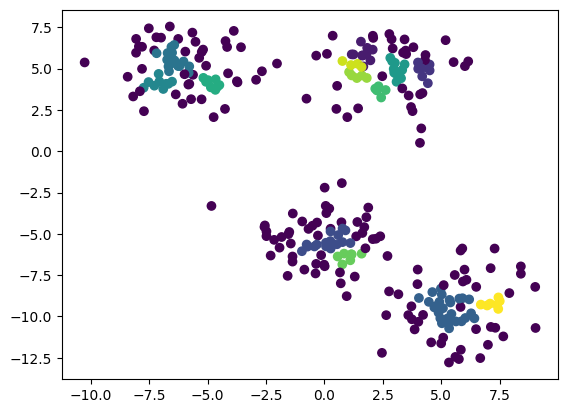

In [ ]:
uniq_labels = np.unique(labels)
n_clusters = len(uniq_labels[uniq_labels != -1])   # шум (-1) кластером не считаем
print(f'метки: {uniq_labels}')
print(f'кластеров: {n_clusters}, точек-шума: {(labels == -1).sum()}')
plt.scatter(X[:,0], X[:,1], c=labels);

По умолчанию `eps=0.5` — для этих данных слишком мало: большая часть точек объявлена шумом, а оставшиеся разбиты на множество мелких кластеров. Увеличим радиус.

eps = 1: кластеров: 4, точек-шума: 39


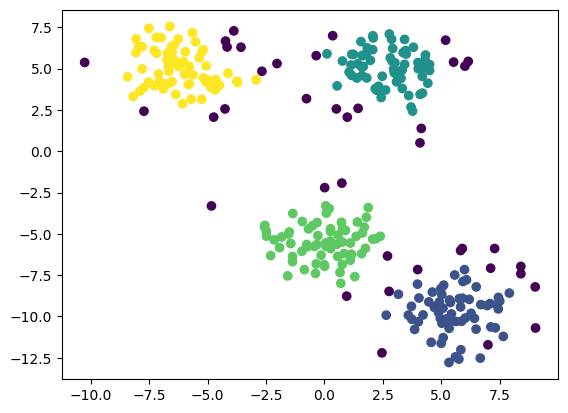

eps = 1.5: кластеров: 4, точек-шума: 5


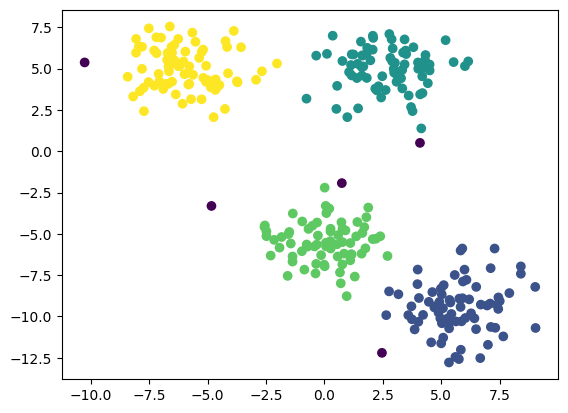

In [ ]:
def run_dbscan(X, eps, min_samples=5):
    # Запускает DBSCAN, печатает число кластеров и рисует результат
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit(X).labels_
    uniq_labels = np.unique(labels)
    n_clusters = len(uniq_labels[uniq_labels != -1])
    print(f'eps = {eps}: кластеров: {n_clusters}, точек-шума: {(labels == -1).sum()}')
    plt.scatter(X[:,0], X[:,1], c=labels)
    plt.show()
    return labels

labels = run_dbscan(X, eps=1)
labels = run_dbscan(X, eps=1.5)

### Как выбрать параметры DBSCAN

**Способ 1: график расстояний до $k$-го соседа.** Возьмём $k$ = `min_samples` и для каждой точки посчитаем расстояние до её $k$-го ближайшего соседа. Отсортируем эти расстояния. У точек внутри кластеров они маленькие, у выбросов — большие. Хорошее значение `eps` — там, где кривая резко идёт вверх («локоть»).

In [ ]:
from sklearn.neighbors import NearestNeighbors

k = 5

# Оценить k ближайших соседей для каждой точки в X
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X)

# Вычислить расстояния для каждого из k ближайших соседей
dists, _ = nn.kneighbors(X, n_neighbors=k)

# Взять расстояния только до k-го соседа
dist_kth = dists[:, k-1]

# Отсортировать расстояния
dist_kth.sort()

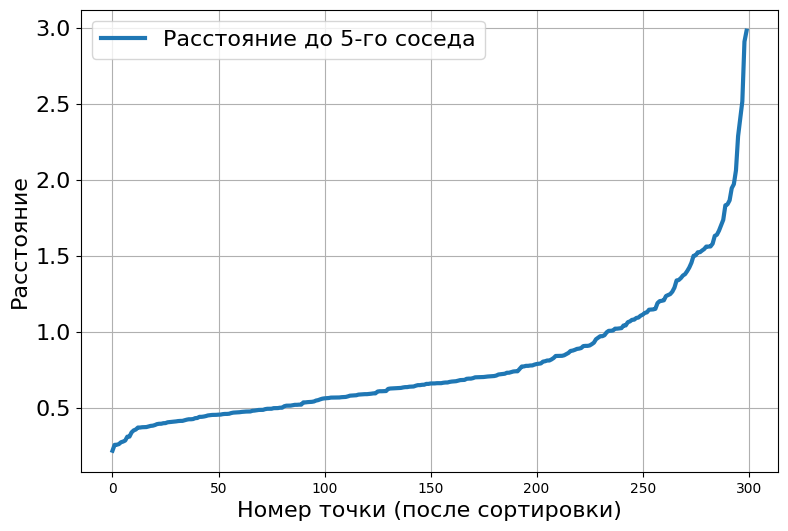

In [ ]:
plt.figure(figsize=(9, 6))
plt.plot(dist_kth, linewidth=3, label=f'Расстояние до {k}-го соседа')
plt.xlabel('Номер точки (после сортировки)', size=16)
plt.ylabel('Расстояние', size=16)
plt.yticks(size=16)
plt.legend(loc='best', fontsize=16)
plt.grid()
plt.show()

**Способ 2: перебор `eps` по силуэту.** Переберём значения `eps` и для каждого посчитаем силуэт и число кластеров. Оформим это в функцию — она понадобится и дальше.

Замечание: здесь точки-шум (метка `-1`) попадают в силуэт как отдельный «кластер». Если шума много, силуэт будет занижен — это стоит учитывать при интерпретации.

In [ ]:
def dbscan_clustering(eps_range, X):
    # Для каждого eps считает силуэт и число кластеров и рисует их на одном графике
    silhouette = []
    clusters = []
    for i in tqdm(eps_range):
        dbscan = DBSCAN(eps=i).fit(X)
        labels = dbscan.labels_
        uniq_labels = np.unique(labels)
        n_clusters = len(uniq_labels[uniq_labels != -1])
        if n_clusters > 1:
            score = silhouette_score(X, labels)
        else:
            score = 0
        silhouette.append(score)
        clusters.append(n_clusters)

    fig, ax1 = plt.subplots()

    color = 'tab:red'
    ax1.plot(eps_range, silhouette, marker='o', color=color)
    ax1.set_xlabel('eps')
    ax1.set_ylabel('silhouette', color=color)
    ax1.tick_params(axis='y', labelcolor=color)

    ax2 = ax1.twinx()  # вторая ось Y с общей осью X

    color = 'tab:blue'
    ax2.plot(eps_range, clusters, marker='o', color=color)
    ax2.set_ylabel('n_clusters', color=color)
    ax2.tick_params(axis='y', labelcolor=color)

    fig.tight_layout()  # чтобы подпись правой оси не обрезалась
    plt.show()

100%|██████████| 19/19 [00:00<00:00, 71.12it/s]


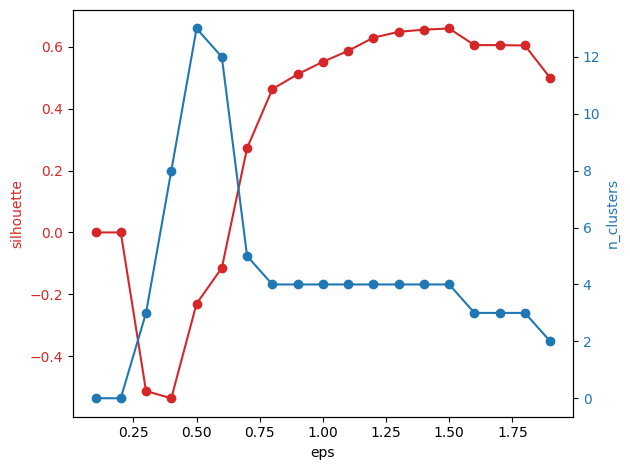

In [ ]:
eps_range = np.arange(0.1, 2, 0.1)
dbscan_clustering(eps_range, X)

Хорошие значения `eps` — там, где силуэт высокий, а число кластеров стабильно (не меняется при небольшом изменении `eps`).

### DBSCAN на сложных формах

Главное преимущество DBSCAN — кластеры произвольной формы. Проверим на тех данных, где k-Means не справился.

#### Два полумесяца

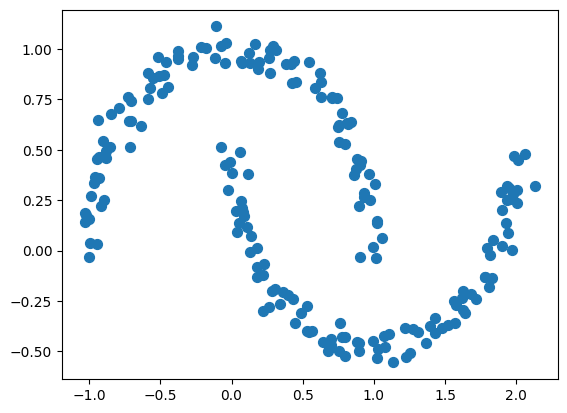

In [ ]:
X, y = make_moons(200, noise=.05, random_state=10)
plt.scatter(X[:, 0], X[:, 1], s=50);

100%|██████████| 19/19 [00:00<00:00, 95.11it/s] 


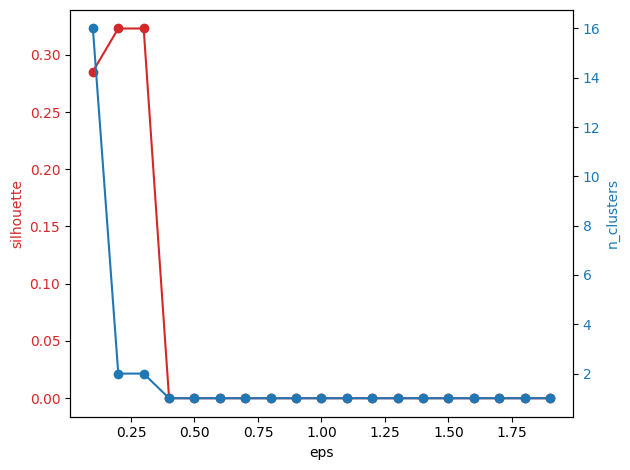

In [ ]:
#eps_range = np.arange(0.01,0.3,0.05)
eps_range = np.arange(0.1,2,0.1)
dbscan_clustering(eps_range, X)

Шаг слишком крупный — посмотрим на диапазон маленьких `eps` подробнее.

100%|██████████| 6/6 [00:00<00:00, 136.19it/s]


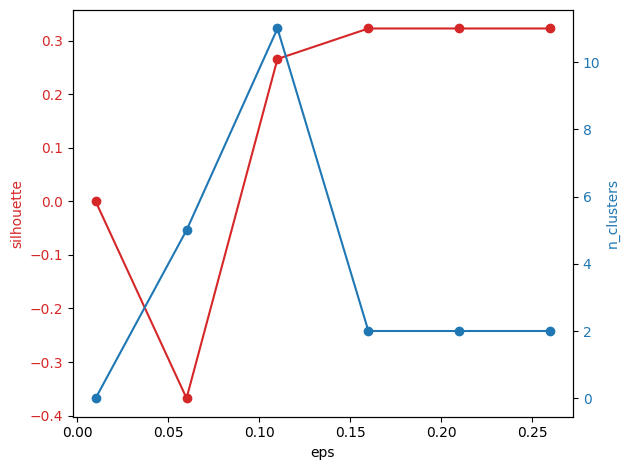

In [ ]:
eps_range = np.arange(0.01,0.3,0.05)
dbscan_clustering(eps_range, X)

eps = 0.2: кластеров: 2, точек-шума: 0


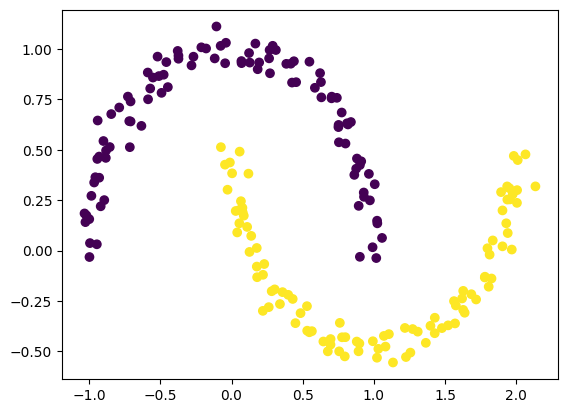

In [ ]:
labels = run_dbscan(X, eps=0.2)

#### Кольца

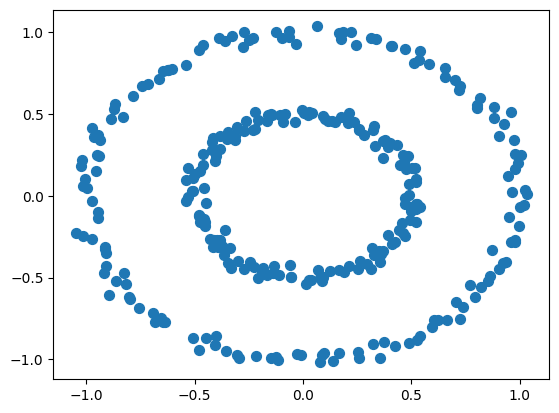

In [ ]:
X, y = make_circles(n_samples=300, noise=0.03, random_state=10, factor=0.5)
plt.scatter(X[:, 0], X[:, 1], s=50);

100%|██████████| 6/6 [00:00<00:00, 79.02it/s]


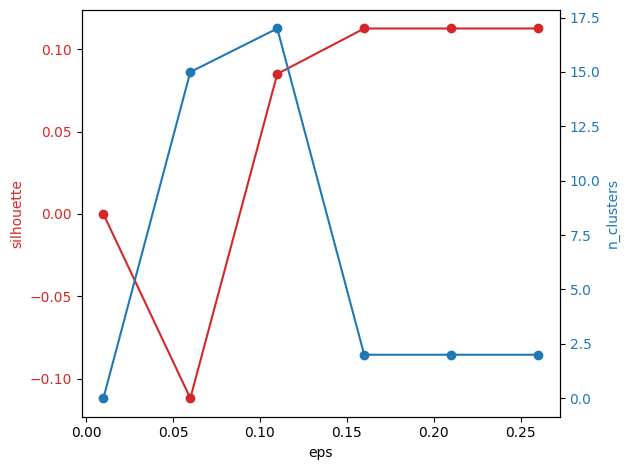

In [ ]:
eps_range = np.arange(0.01,0.3,0.05)
dbscan_clustering(eps_range, X)

eps = 0.2: кластеров: 2, точек-шума: 0


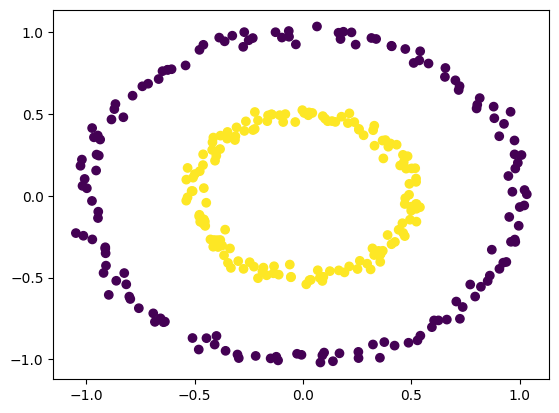

In [ ]:
labels = run_dbscan(X, eps=0.2)

#### Вытянутые облака (анизотропные данные)

Для DBSCAN это трудный случай: облака касаются друг друга, и плотность между ними почти такая же, как внутри. Посмотрим, как результат зависит от `eps`.

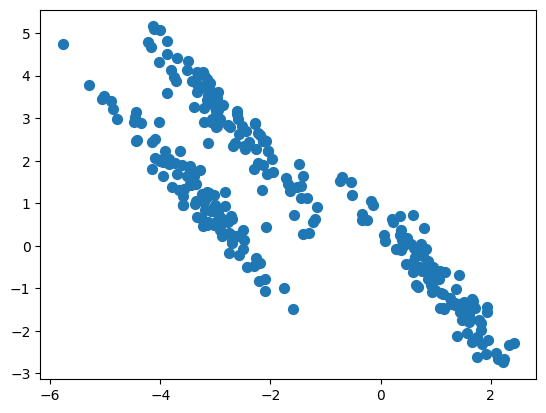

In [ ]:
X, y_true = make_blobs(n_samples=300, centers=3, random_state=170)
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X = np.dot(X, transformation)
plt.scatter(X[:, 0], X[:, 1], s=50);

100%|██████████| 10/10 [00:00<00:00, 115.12it/s]


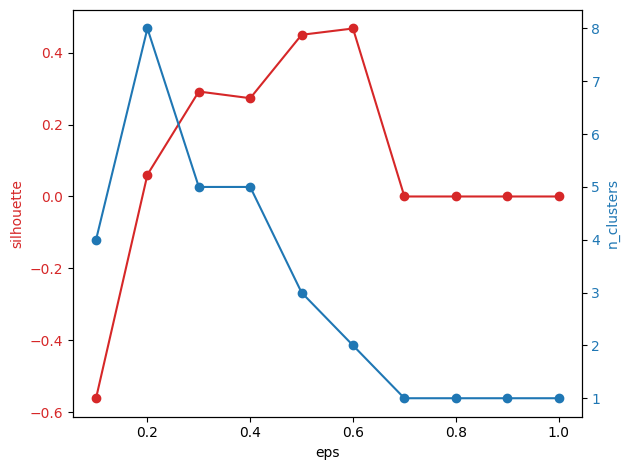

In [ ]:
eps_range = np.arange(0.1,1.1,0.1)
dbscan_clustering(eps_range, X)

eps = 0.5: кластеров: 3, точек-шума: 2


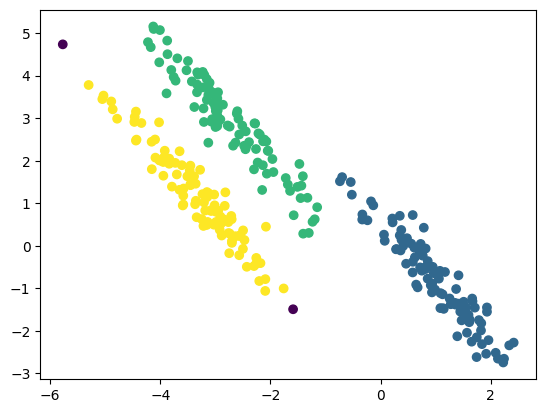

eps = 0.6: кластеров: 2, точек-шума: 1


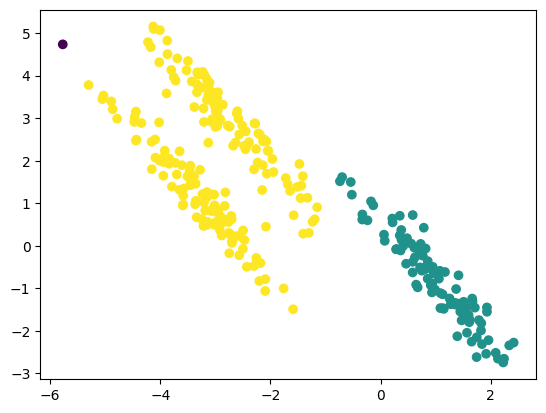

eps = 0.8: кластеров: 1, точек-шума: 1


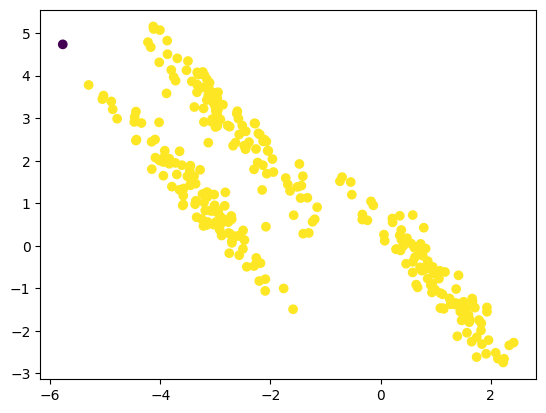

In [ ]:
for eps in [0.5, 0.6, 0.8]:
    labels = run_dbscan(X, eps=eps)

При `eps = 0.5` DBSCAN находит все три облака, но уже при `eps = 0.6` два из них сливаются, а при `eps = 0.8` остаётся один кластер. Подходящее значение лежит в узком диапазоне, и угадать его без разметки трудно: DBSCAN плохо работает, когда **плотность кластеров разная** или между ними нет разреженной области.

### HDBSCAN

Главная сложность DBSCAN — выбор `eps`, причём один радиус на всю выборку. **HDBSCAN** (Hierarchical DBSCAN) решает эту проблему: он перебирает все значения `eps` сразу, строит иерархию кластеров и оставляет самые «устойчивые». Основной параметр — `min_cluster_size`, минимальный размер кластера; `eps` задавать не нужно, и кластеры могут иметь разную плотность. В `sklearn` он есть начиная с версии 1.3.

кластеров: 3, точек-шума: 66


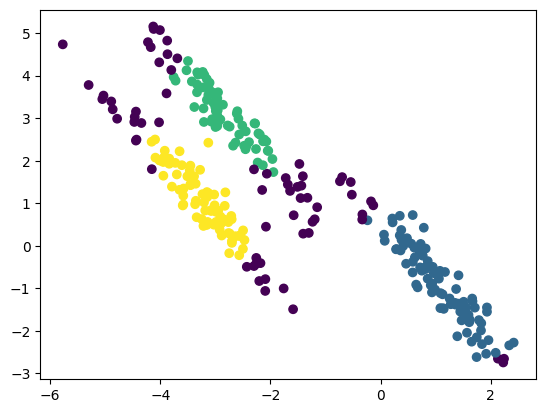

In [ ]:
from sklearn.cluster import HDBSCAN

labels = HDBSCAN(min_cluster_size=15).fit_predict(X)
print(f'кластеров: {len(np.unique(labels[labels != -1]))}, точек-шума: {(labels == -1).sum()}')
plt.scatter(X[:,0], X[:,1], c=labels);

HDBSCAN находит три облака без подбора `eps`. Зато он осторожнее и относит к шуму больше точек на краях облаков: «разреженные» края он не считает частью кластера.

## Иерархическая кластеризация <a id="hierarchical"></a>

Иерархическая кластеризация — один из популярных и простых для понимания методов кластеризации.

Данный метод делится на два типа:
1. Агломеративный (алгоритм объединяет два меньших кластера в один на каждой итерации)
2. Дивизивный (алгоритм разделяет один кластер на два меньших на каждой итерации)

Рассмотрим агломеративную иерархическую кластеризацию (дивизивная рассматривается по аналогии).

**Агломеративная иерархическая кластеризация:**
В данном методе изначально каждый объект данных рассматривается как отдельный кластер. На каждой итерации похожие кластеры объединяются с другими, пока не останется один кластер или K кластеров.

Базовый алгоритм агломеративной кластеризации прост:
1. Вычислить матрицу близости
2. Считать каждую точку данных отдельным кластером
3. **Повтор:** объединить два наиближайших кластера и обновить матрицу близости
4. До тех пор, пока не останется единственный кластер

Резюме:
1. Можно выбрать любое число кластеров, остановив алгоритм в нужный момент
2. Результат сильно зависит от того, как считать расстояние между кластерами (параметр `linkage`, см. ниже)

Иерархическую кластеризацию удобно визуализировать с помощью дендрограммы.

**Как считать расстояние между кластерами** (параметр `linkage`):
- `single` — расстояние между **ближайшими** точками двух кластеров. Умеет находить вытянутые кластеры сложной формы, но склонен «склеивать» кластеры через цепочки точек;
- `complete` — расстояние между **самыми далёкими** точками;
- `average` — **среднее** расстояние между всеми парами точек;
- `ward` (по умолчанию в `sklearn`) — объединяем те кластеры, при слиянии которых **внутрикластерная дисперсия растёт меньше всего**. Похож на k-Means и тоже любит компактные «шарообразные» кластеры.

### Дендрограмма

Сгенерируем 4 облака и построим дендрограмму. По вертикали — расстояние, на котором кластеры объединились. Длинные вертикальные отрезки означают, что объединяются далёкие друг от друга кластеры, — горизонтальная линия, проведённая через них, задаёт разумное число кластеров.

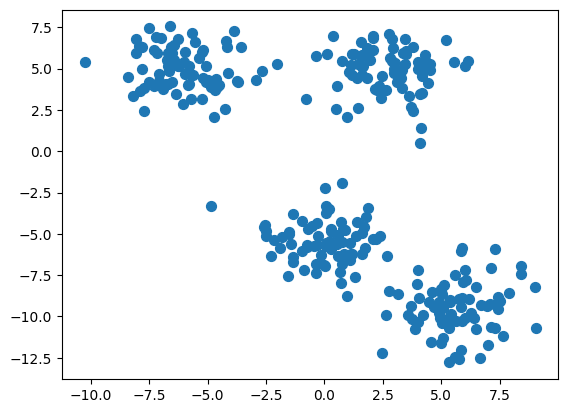

In [ ]:
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=1.5, random_state=10)
plt.scatter(X[:, 0], X[:, 1], s=50);

Строим дендрограмму с `linkage='ward'`. Внизу — отдельные точки, каждое горизонтальное «коромысло» — слияние двух кластеров, его высота — расстояние, на котором они объединились.

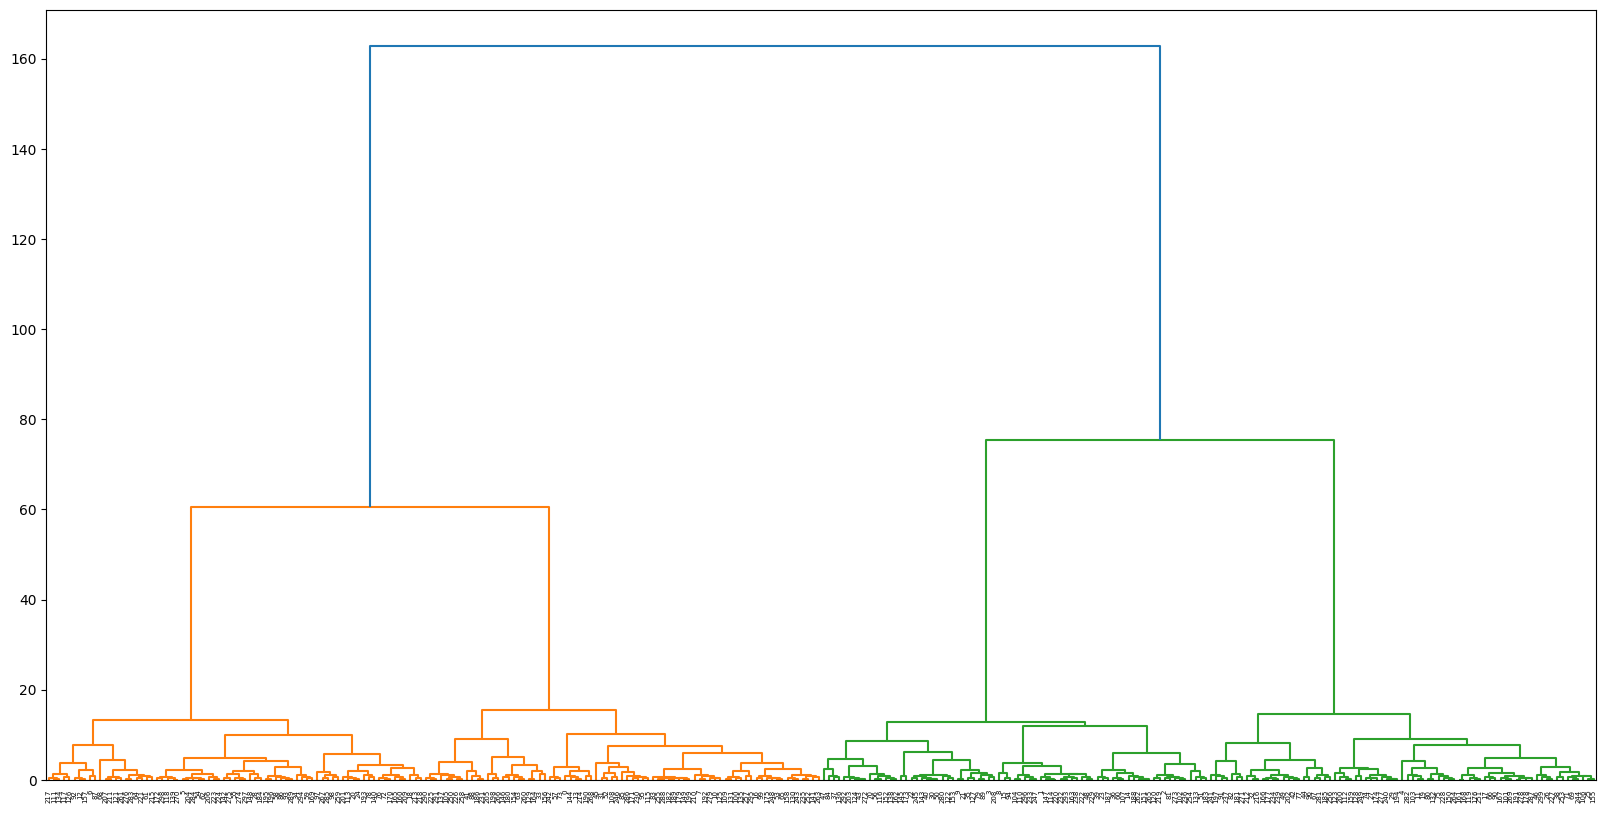

In [ ]:
plt.figure(figsize=(20,10))
linkage_ = linkage(X, method='ward')
dendrogram_ = dendrogram(linkage_)

Иерархия уже построена — число кластеров можно выбрать, просто «срезав» дерево на нужном уровне:

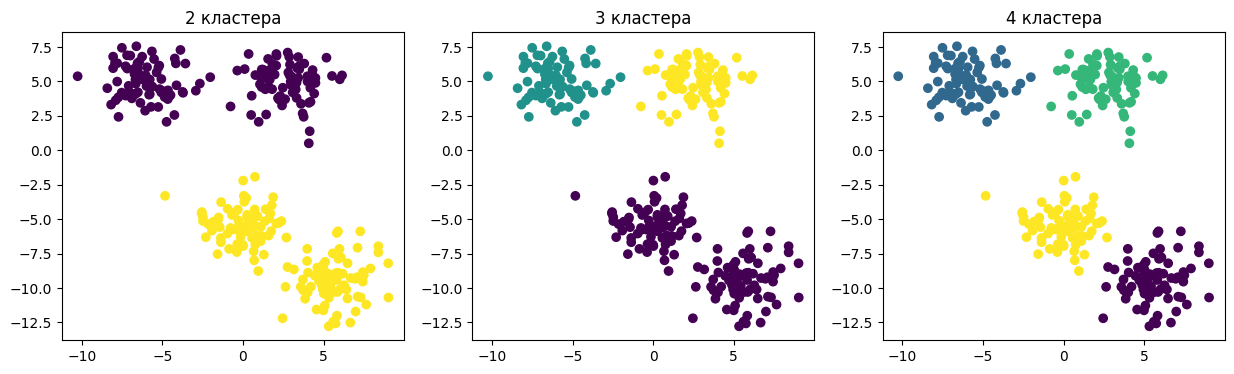

In [ ]:
plt.figure(figsize=(15, 4))
for j, n in enumerate([2, 3, 4]):
    labels = AgglomerativeClustering(n_clusters=n).fit(X).labels_
    plt.subplot(1, 3, j + 1)
    plt.scatter(X[:,0], X[:,1], c=labels)
    plt.title(f'{n} кластера')
plt.show()

### Выбор числа кластеров по силуэту

Как и для k-Means, переберём число кластеров от 2 до 10 и для каждого посчитаем силуэт. Лучшее число кластеров — там, где силуэт максимален.

In [ ]:
silhouette = []
for i in tqdm(range(2,11)):
    agg = AgglomerativeClustering(n_clusters=i).fit(X)
    labels = agg.labels_
    score = silhouette_score(X, labels)
    silhouette.append(score)

100%|██████████| 9/9 [00:00<00:00, 42.90it/s]


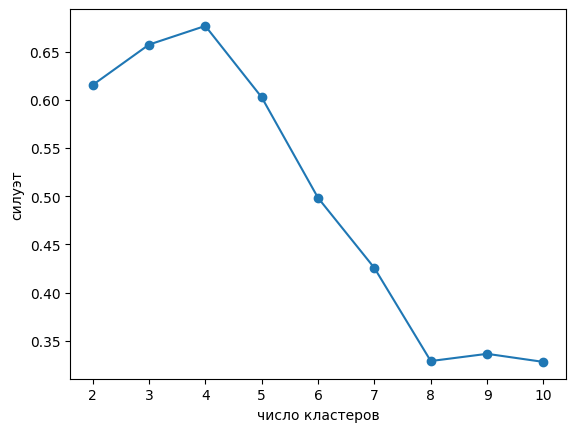

In [ ]:
plt.plot(range(2,11), silhouette, marker='o')
plt.xlabel('число кластеров')
plt.ylabel('силуэт');

### Сложные формы данных

Сравним разные способы `linkage` на тех же сложных датасетах.

Функция `agg_clustering` запускает агломеративную кластеризацию с заданными числом кластеров и способом `linkage` и рисует результат. По умолчанию `linkage='single'`.

In [ ]:
def agg_clustering(n_clusters, X, linkage = 'single'):
    agg = AgglomerativeClustering(n_clusters=n_clusters, linkage = linkage).fit(X)
    labels = agg.labels_

    plt.scatter(X[:,0], X[:,1], c=labels)
    plt.title(str(n_clusters)+' кластера')
    plt.show();

In [ ]:
AgglomerativeClustering?

#### Два полумесяца

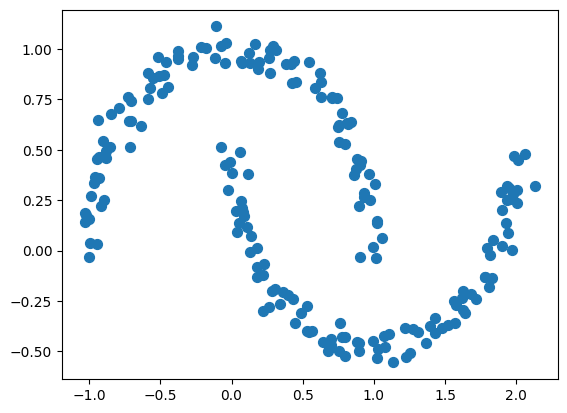

In [ ]:
X, y = make_moons(200, noise=.05, random_state=10)
plt.scatter(X[:, 0], X[:, 1], s=50);

Сравним `single` и `ward` при правильном числе кластеров (2). `single` объединяет кластеры по ближайшим точкам и может «пройти» вдоль полумесяца, а `ward` стремится к компактным кластерам и режет полумесяцы поперёк.

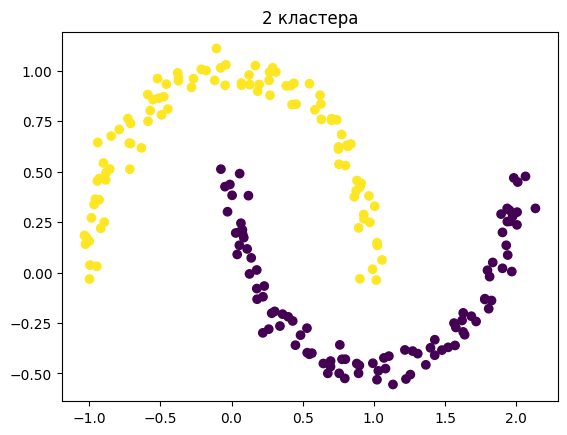

In [ ]:
agg_clustering(2,X, 'single')

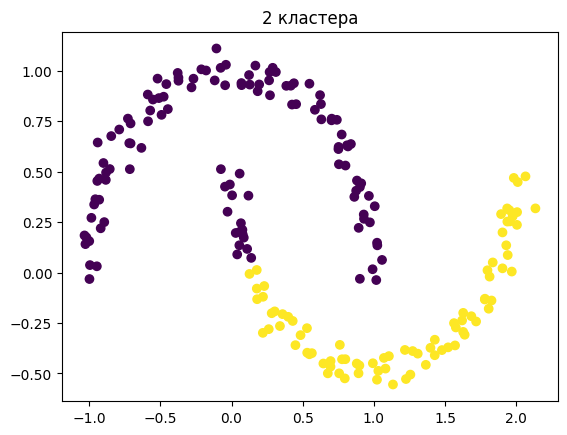

In [ ]:
agg_clustering(2,X, 'ward')

А что будет, если задать лишний кластер? Посмотрите, какой кусок `single` выделит в отдельный кластер.

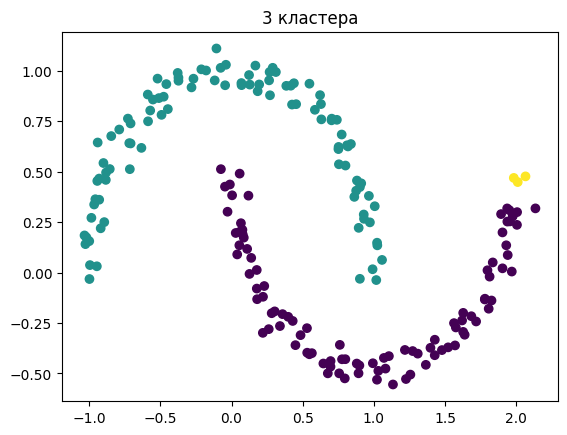

In [ ]:
agg_clustering(3,X)

Подберём число кластеров по силуэту для `single` и для `ward`:

In [ ]:
silhouette = []
for i in tqdm(range(2,11)):
    agg = AgglomerativeClustering(n_clusters=i, linkage = 'single').fit(X)
    labels = agg.labels_
    score = silhouette_score(X, labels)
    silhouette.append(score)

100%|██████████| 9/9 [00:00<00:00, 123.07it/s]


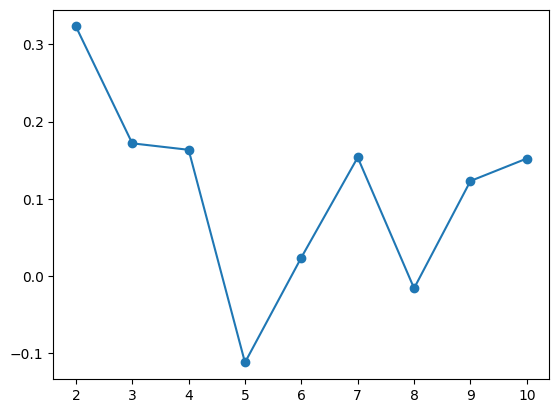

In [ ]:
plt.plot(range(2,11), silhouette, marker='o');

In [ ]:
silhouette = []
for i in tqdm(range(2,11)):
    agg = AgglomerativeClustering(n_clusters=i, linkage = 'ward').fit(X)
    labels = agg.labels_
    score = silhouette_score(X, labels)
    silhouette.append(score)

100%|██████████| 9/9 [00:00<00:00, 81.69it/s]


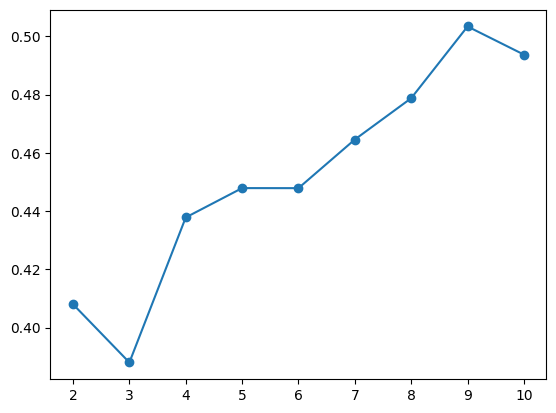

In [ ]:
plt.plot(range(2,11), silhouette, marker='o');

Для `single` силуэт максимален при 2 кластерах — это правильный ответ. А для `ward` силуэт растёт с числом кластеров и подсказывает разбить полумесяцы на 9 частей: `ward`, как и k-Means, режет данные на компактные куски. Значит, метрику нужно смотреть вместе с картинкой и пониманием того, какие кластеры ищет алгоритм.

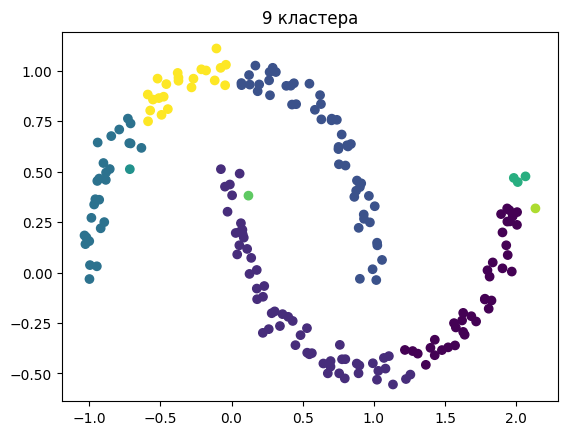

In [ ]:
agg_clustering(9,X)

#### Кольца

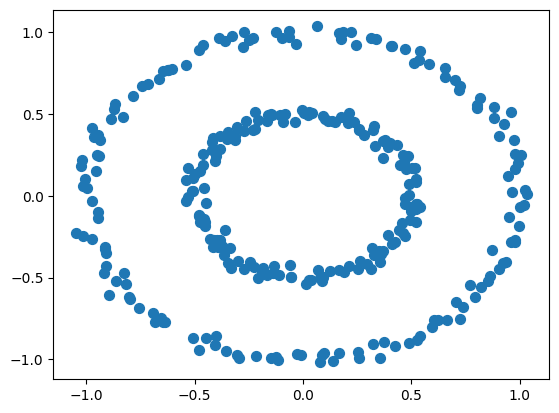

In [ ]:
X, y = make_circles(n_samples=300, noise=0.03, random_state=10, factor=0.5)
plt.scatter(X[:, 0], X[:, 1], s=50);

На кольцах та же история: `ward` делит плоскость пополам, а `single` может разделить внутреннее и внешнее кольцо, потому что точки внутри каждого кольца стоят плотной цепочкой.

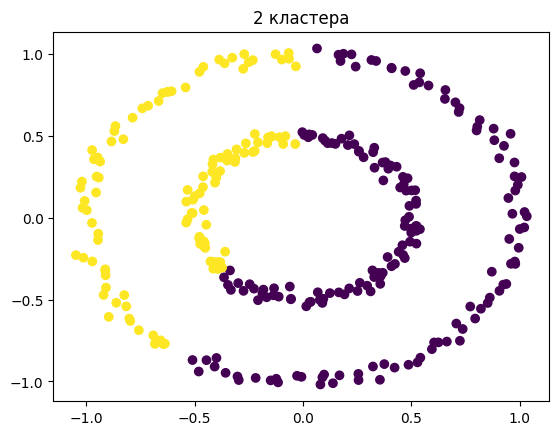

In [ ]:
agg_clustering(2,X, 'ward')

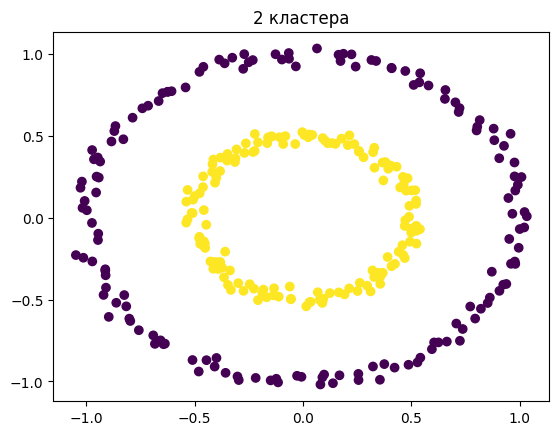

In [ ]:
agg_clustering(2,X, 'single')

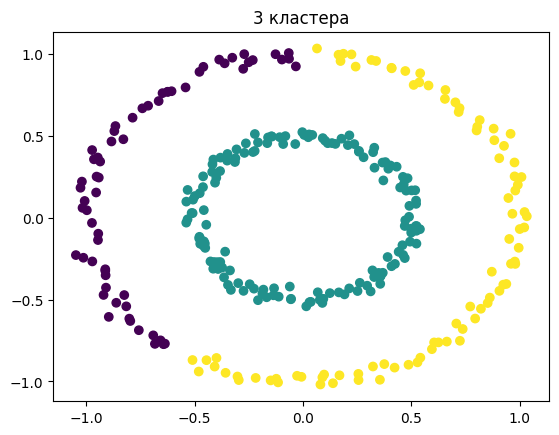

In [ ]:
agg_clustering(3,X, 'single')

Подберём число кластеров по силуэту для `single`. Силуэт рассчитан на компактные кластеры, поэтому для колец он ошибается: максимум получается при 3 кластерах, а не при правильных 2.

In [ ]:
silhouette = []
for i in tqdm(range(2,21)):
    agg = AgglomerativeClustering(n_clusters=i, linkage = 'single').fit(X)
    labels = agg.labels_
    score = silhouette_score(X, labels)
    silhouette.append(score)

100%|██████████| 19/19 [00:00<00:00, 76.09it/s]


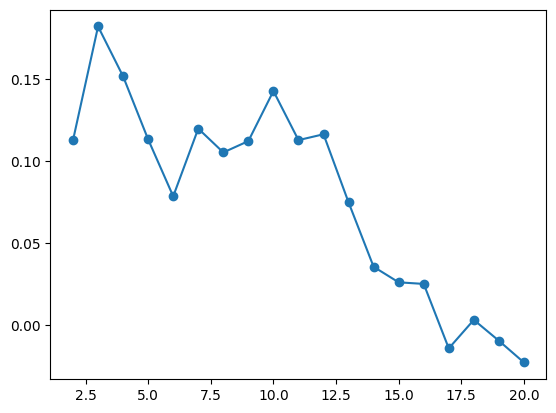

In [ ]:
plt.plot(range(2,21), silhouette, marker='o');

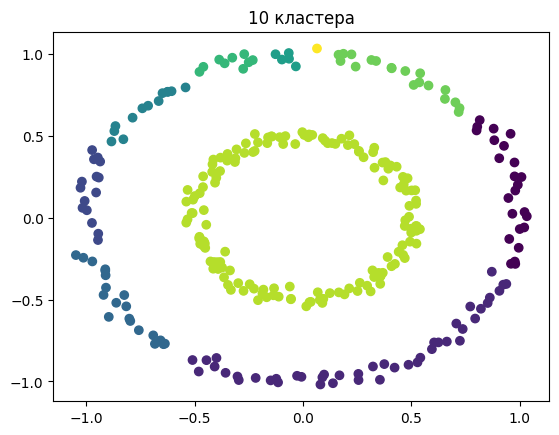

In [ ]:
agg_clustering(10,X)

#### Вытянутые облака (анизотропные данные)

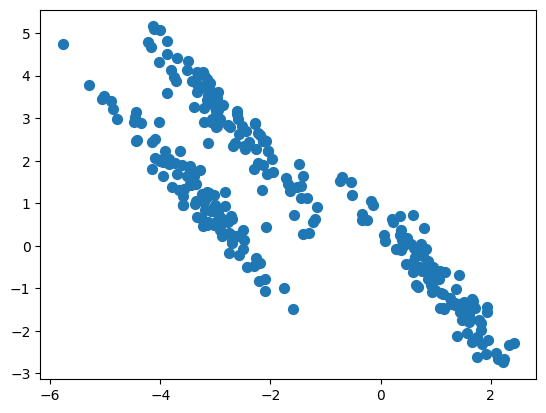

In [ ]:
X, y_true = make_blobs(n_samples=300, centers=3, random_state=170)
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X = np.dot(X, transformation)
plt.scatter(X[:, 0], X[:, 1], s=50);

Здесь используется `linkage='single'` (значение по умолчанию в нашей функции). Облака вытянуты и почти касаются друг друга, поэтому `single` может склеить их через цепочку близких точек.

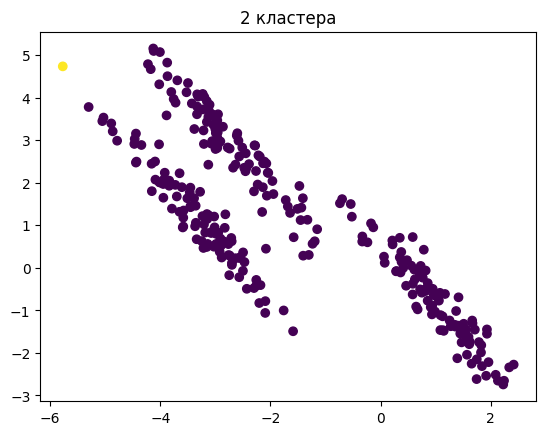

In [ ]:
agg_clustering(2,X)

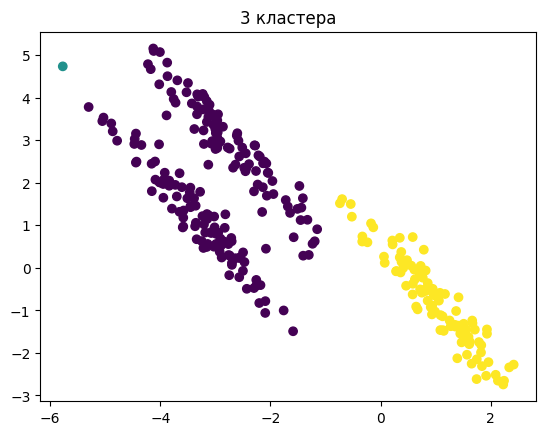

In [ ]:
agg_clustering(3,X)

Для силуэта здесь используется `AgglomerativeClustering` без параметров, то есть `linkage='ward'`. Силуэт максимален при 2 кластерах, хотя облаков 3: два соседних вытянутых облака для него выглядят как один кластер.

In [ ]:
silhouette = []
for i in tqdm(range(2,11)):
    agg = AgglomerativeClustering(n_clusters=i).fit(X)
    labels = agg.labels_
    score = silhouette_score(X, labels)
    silhouette.append(score)

100%|██████████| 9/9 [00:00<00:00, 75.87it/s]


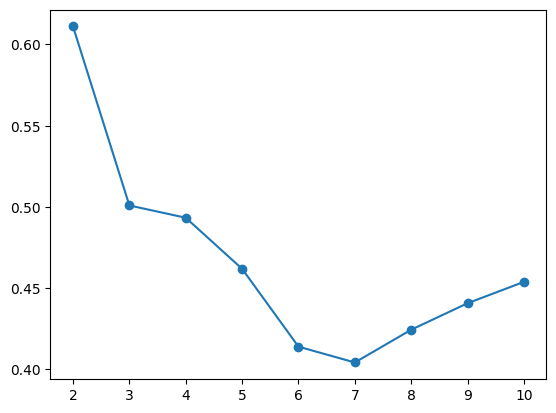

In [ ]:
plt.plot(range(2,11), silhouette, marker='o');

### Итоги по алгоритмам

| | k-Means | DBSCAN | Иерархическая |
|---|---|---|---|
| Число кластеров | задаётся | получается само | выбирается после обучения |
| Форма кластеров | выпуклые, «шарики» | любая | зависит от `linkage` |
| Выбросы | нет (каждая точка в кластере) | выделяет как шум | нет |
| Главная сложность | выбор $K$, чувствительность к инициализации | выбор `eps`, разная плотность | $O(N^2)$ по памяти, выбор `linkage` |

# Кластеризация на реальных данных <a id="real"></a>

[World Happiness Report](https://www.kaggle.com/unsdsn/world-happiness) — ежегодный доклад о состоянии «счастья» в мире. Первый доклад вышел в 2012 году; в нём страны ранжируются по уровню счастья, и он публикуется в ООН к Международному дню счастья (20 марта). Правительства и организации всё чаще используют такие показатели благополучия при принятии решений. В докладе для каждой страны есть итоговая оценка и факторы, которые её объясняют: ВВП на душу населения, социальная поддержка, ожидаемая продолжительность здоровой жизни, свобода выбора, щедрость, восприятие коррупции.

Попробуем разбить страны на группы по этим показателям.

In [ ]:
!wget -O data.csv https://drive.usercontent.google.com/download?id=1b6bK8V-2fKfKQ8z8zqYQbkjRasUaPFiZ&export=download&authuser=0&confirm=t&uuid=09175432-4e29-4265-98b2-03b28c9212c5&at=AO7h07eejM3soJYP_v4aDNZKJhyf:1725021024305

--2026-11-11 02:09:41--  https://drive.usercontent.google.com/download?id=1b6bK8V-2fKfKQ8z8zqYQbkjRasUaPFiZ
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 74.125.137.132, 2607:f8b0:4023:c0d::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|74.125.137.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8822 (8.6K) [application/octet-stream]
Saving to: ‘data.csv’

data.csv            100%[===================>]   8.62K  --.-KB/s    in 0s      

2026-11-11 02:09:43 (46.4 MB/s) - ‘data.csv’ saved [8822/8822]



Загружаем данные: каждая строка — страна, столбцы — итоговая оценка счастья и факторы, которые её объясняют.

In [ ]:
data = pd.read_csv('data.csv')

In [ ]:
data.shape

(156, 9)

In [ ]:
data.head()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


Столбец `Overall rank` — это просто место страны в рейтинге: он однозначно определяется оценкой `Score` и не несёт новой информации, поэтому удаляем его.

In [ ]:
data['Overall rank'].nunique()

156

In [ ]:
data.drop('Overall rank', axis=1, inplace=True)

Название страны — не признак, а идентификатор. Сохраним его отдельно в `country`, чтобы потом посмотреть, какие страны попали в каждый кластер, и удалим из данных.

In [ ]:
data['Country or region'].nunique()

156

In [ ]:
country = data['Country or region']

In [ ]:
data.drop('Country or region', axis=1, inplace=True)

Посмотрим на распределения признаков и попарные зависимости: есть ли выбросы, сильно ли признаки различаются по масштабу, видны ли «на глаз» группы стран.

In [ ]:
data.describe()

,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,5.407096,0.905147,1.208814,0.725244,0.392571,0.184846,0.110603
std,1.113120,0.398389,0.299191,0.242124,0.143289,0.095254,0.094538
min,2.853000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.544500,0.602750,1.055750,0.547750,0.308000,0.108750,0.047000
50%,5.379500,0.960000,1.271500,0.789000,0.417000,0.177500,0.085500
75%,6.184500,1.232500,1.452500,0.881750,0.507250,0.248250,0.141250
max,7.769000,1.684000,1.624000,1.141000,0.631000,0.566000,0.453000


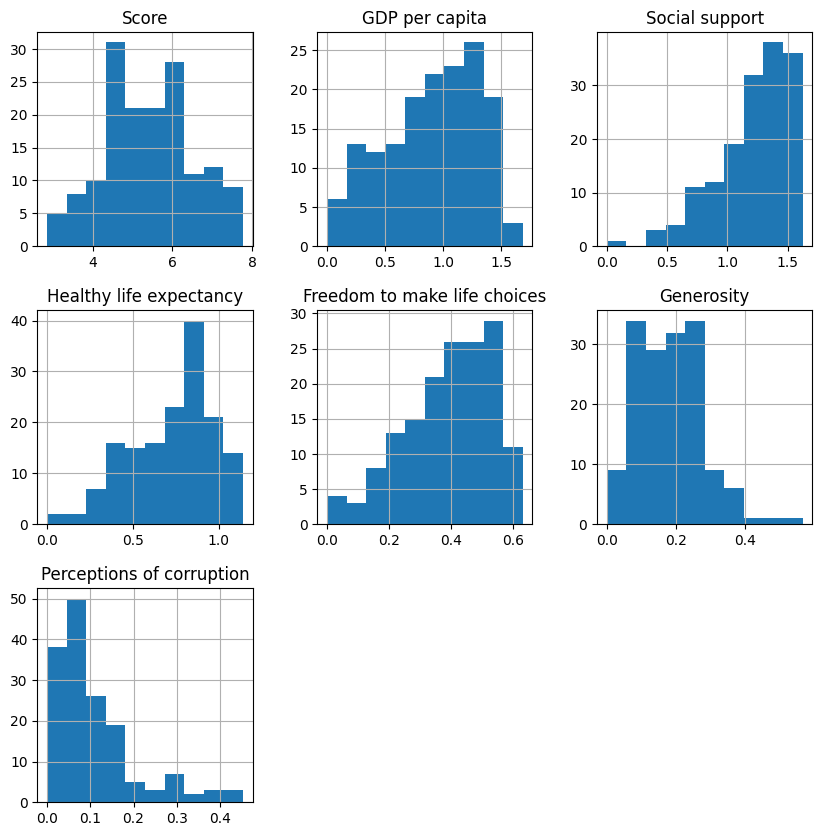

In [ ]:
data.hist(figsize=(10,10));

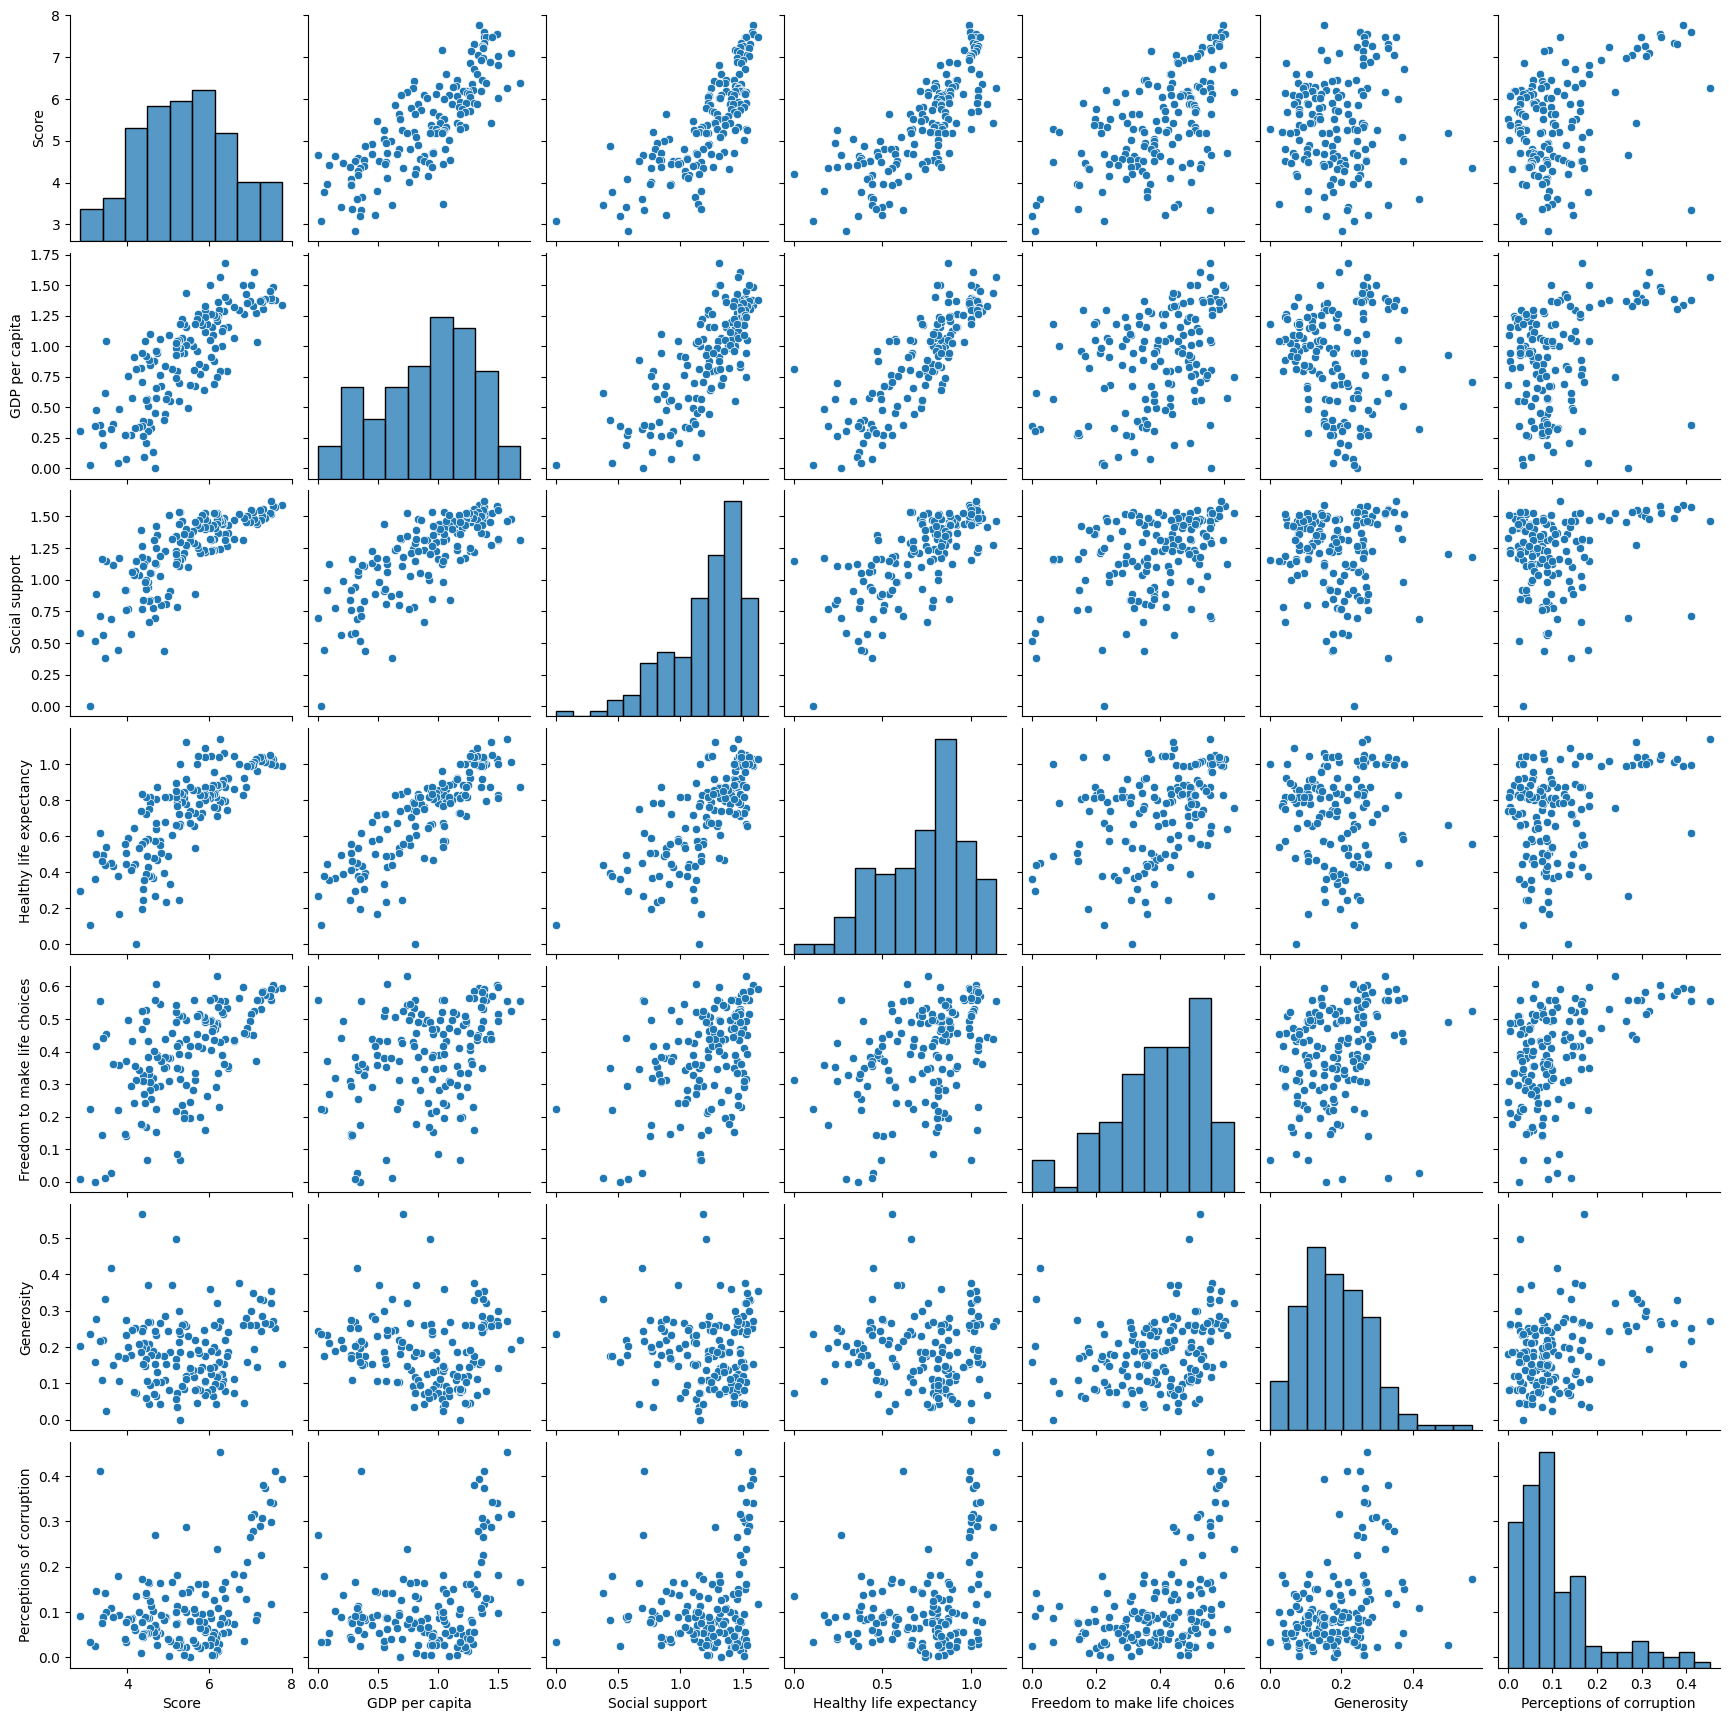

In [ ]:
sns.pairplot(data);

## 1. Корреляция

Если признаки сильно скоррелированы, они дублируют друг друга и при кластеризации фактически получают больший вес. Посмотрим на матрицу корреляций (показываем только нижний треугольник — матрица симметрична).

In [ ]:
corr = data.corr()

In [ ]:
mask = np.triu(np.ones_like(corr, dtype=bool))

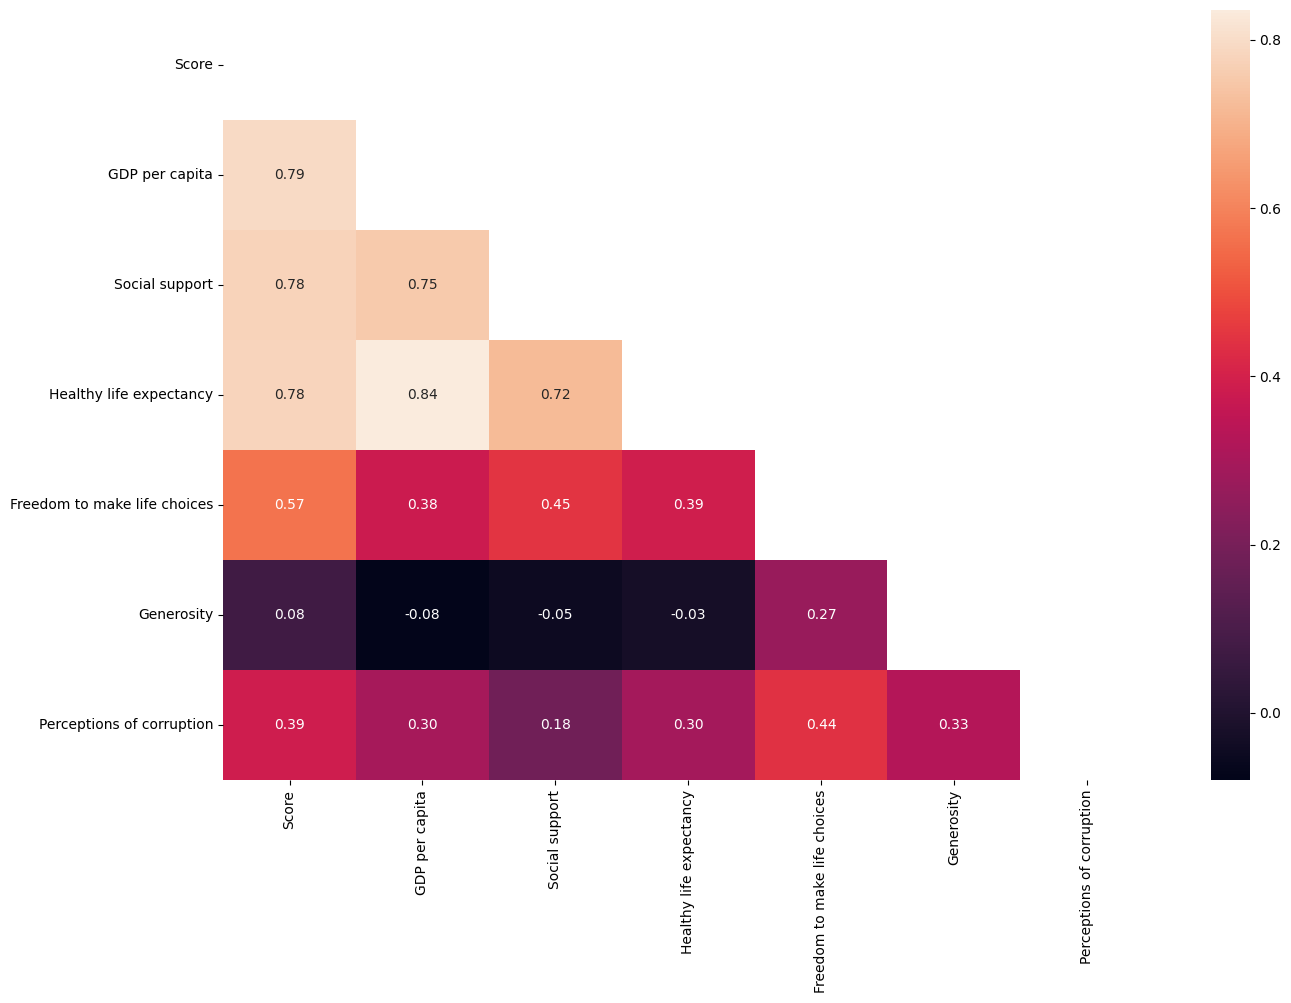

In [ ]:
plt.figure(figsize=(15,10))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f');

## 2. Нормализация

Кластеризация опирается на расстояния, поэтому признаки должны быть в одном масштабе — иначе признак с самыми большими значениями будет доминировать.

Ящики с усами до нормализации: видно, что признаки имеют разный масштаб.

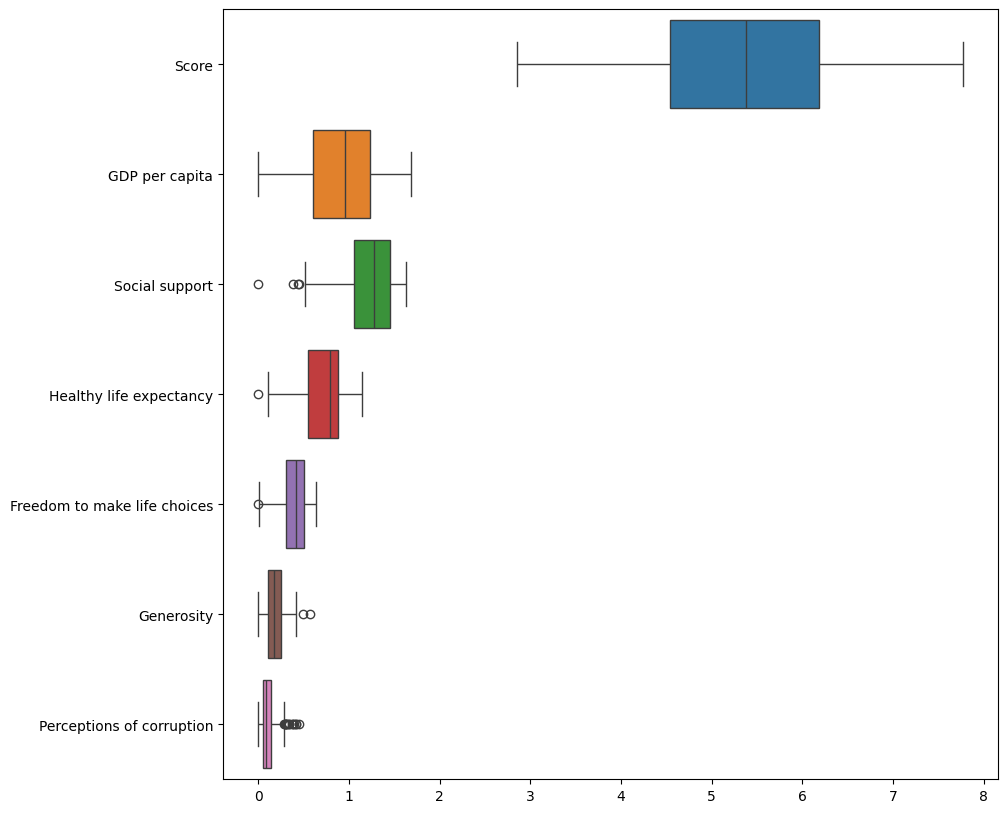

In [ ]:
plt.figure(figsize=(10,10))
sns.boxplot(data=data, orient='h');

`MinMaxScaler` переводит каждый признак в отрезок $[0, 1]$: $x' = \dfrac{x - \min}{\max - \min}$. После этого все признаки вносят в расстояние сопоставимый вклад.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
scaler = MinMaxScaler()

In [ ]:
X_scaled = scaler.fit_transform(data)

In [ ]:
data_scaled = pd.DataFrame(X_scaled, columns=data.columns)

In [ ]:
data_scaled.head()

,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1.000000,0.795724,0.977217,0.864154,0.944532,0.270318,0.867550
1,0.965622,0.821259,0.968596,0.872918,0.938193,0.445230,0.905077
2,0.956265,0.883610,0.974138,0.900964,0.955626,0.478799,0.752759
3,0.944060,0.819477,1.000000,0.899211,0.936609,0.625442,0.260486
4,0.942840,0.828979,0.937192,0.875548,0.882726,0.568905,0.657837


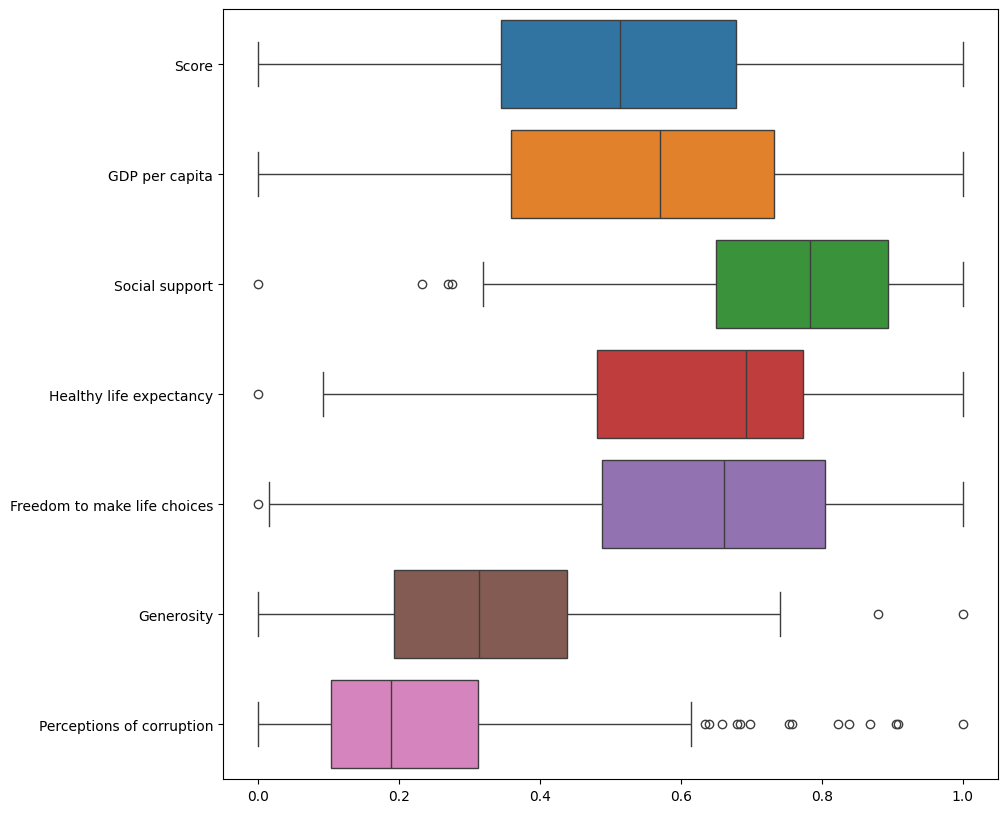

In [ ]:
plt.figure(figsize=(10,10))
sns.boxplot(data=data_scaled, orient='h');

## 3. Снижение размерности для визуализации

Признаков больше двух, поэтому, чтобы нарисовать результат, отобразим страны на плоскость методом t-SNE. Он сохраняет близость соседних точек и используется здесь только для картинки — кластеризацию мы делаем в исходном пространстве признаков.

t-SNE строит двумерное представление, в котором близкие в исходном пространстве страны оказываются рядом. Дальше мы будем раскрашивать эту картинку метками кластеров. Оси t-SNE не имеют смысла, а расстояния между далёкими группами на картинке не стоит интерпретировать.

In [ ]:
from sklearn.manifold import TSNE

In [ ]:
tsne = TSNE(n_components=2, random_state=10)

In [ ]:
X_scaled.shape

(156, 7)

In [ ]:
X_tsne = tsne.fit_transform(X_scaled)

In [ ]:
X_tsne.shape

(156, 2)

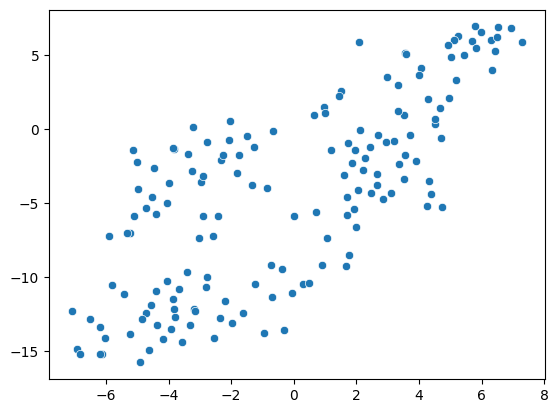

In [ ]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1]);

## 4. Кластеризация

### 4.1 DBSCAN

Подбираем `eps` по графику силуэта и числа кластеров, постепенно сужая диапазон: сначала грубый перебор, потом приближаемся к интересной области с более мелким шагом.

100%|██████████| 90/90 [00:00<00:00, 346.67it/s]


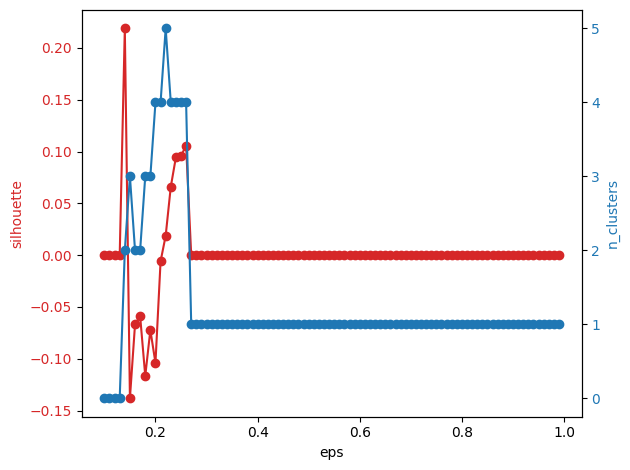

In [ ]:
eps_range = np.arange(0.1,1,0.01)
dbscan_clustering(eps_range, X_scaled)

100%|██████████| 31/31 [00:00<00:00, 340.97it/s]


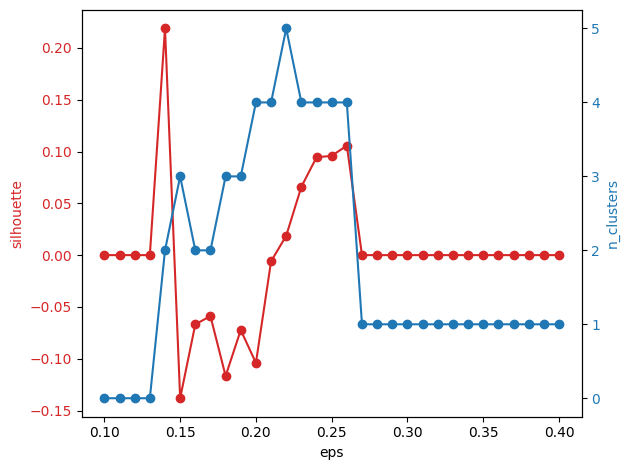

In [ ]:
eps_range = np.arange(0.1,0.4,0.01)
dbscan_clustering(eps_range, X_scaled)

100%|██████████| 20/20 [00:00<00:00, 319.54it/s]


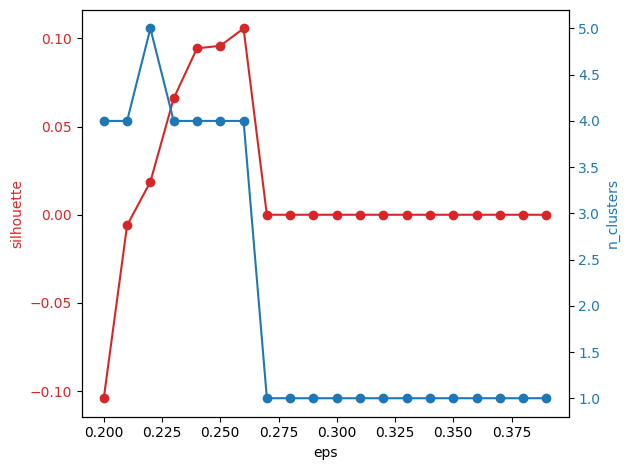

In [ ]:
eps_range = np.arange(0.2,0.4,0.01)
dbscan_clustering(eps_range, X_scaled)

100%|██████████| 6/6 [00:00<00:00, 202.66it/s]


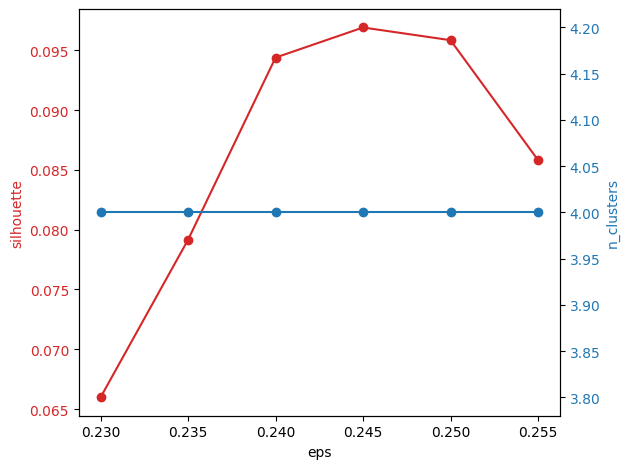

In [ ]:
eps_range = np.arange(0.23,0.26,0.005)
dbscan_clustering(eps_range, X_scaled)

При `eps < 0.14` почти все страны — шум (0 кластеров), при `eps > 0.27` все сливаются в один кластер. Стабильное число кластеров (4) держится при `eps` от 0.23 до 0.26, и в этом диапазоне силуэт максимален при `eps ≈ 0.245`. Но даже лучший силуэт около 0.1, то есть кластеры получаются слабо разделёнными.

Обучаем DBSCAN с выбранным `eps` и смотрим, как кластеры выглядят на картинке t-SNE. Метка `-1` — страны, которые DBSCAN посчитал шумом (выбросами).

In [ ]:
dbscan = DBSCAN(eps=0.245).fit(X_scaled)
labels = dbscan.labels_

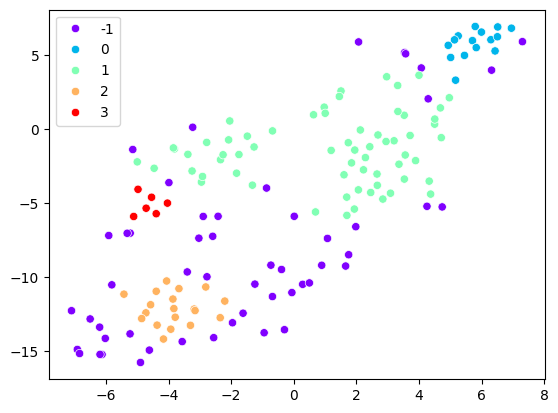

In [ ]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=labels, palette='rainbow');

Добавляем метки в таблицу и смотрим на размеры кластеров (доля стран в каждом). Если почти все страны попали в один кластер, а остальное — шум, кластеризация мало что даёт.

In [ ]:
data['labels'] = labels

In [ ]:
data['labels'].value_counts(normalize=True)

,proportion
labels,
1,0.403846
-1,0.339744
2,0.121795
0,0.096154
3,0.038462


Треть стран (34%) DBSCAN отнёс к шуму, самый большой кластер содержит 40% стран, остальные три — от 4% до 12%. Для 156 стран это много шума: плотность точек неравномерная, и одним `eps` её не описать.

**Интерпретация кластеров.** Для каждого признака рисуем ящики с усами по кластерам: так видно, чем кластеры отличаются друг от друга (например, ВВП или продолжительностью жизни).

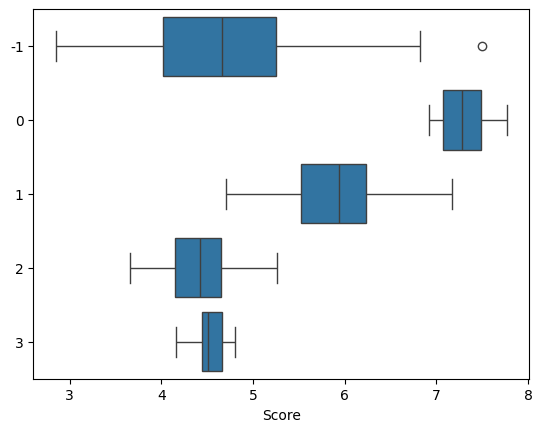

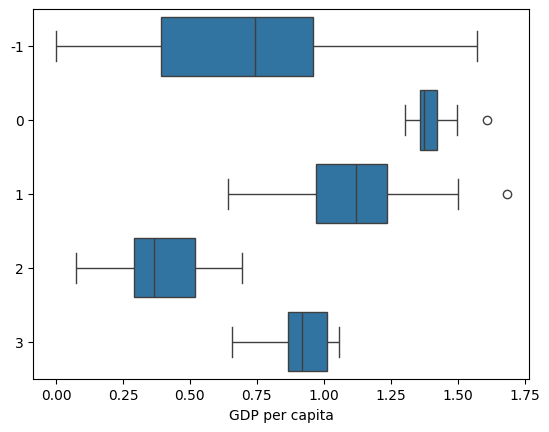

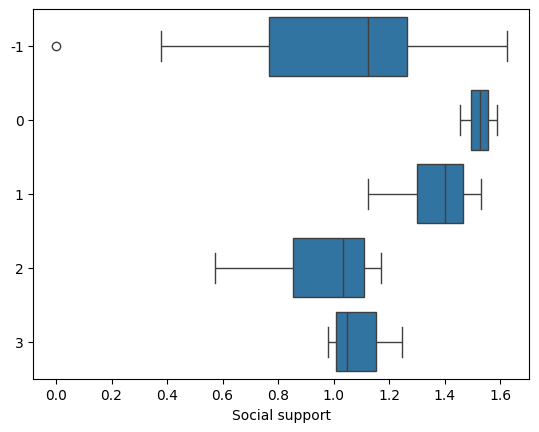

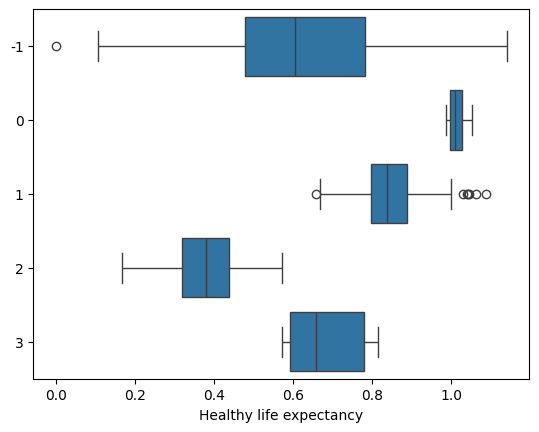

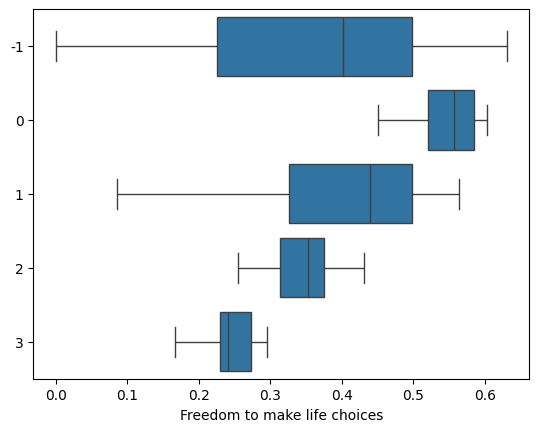

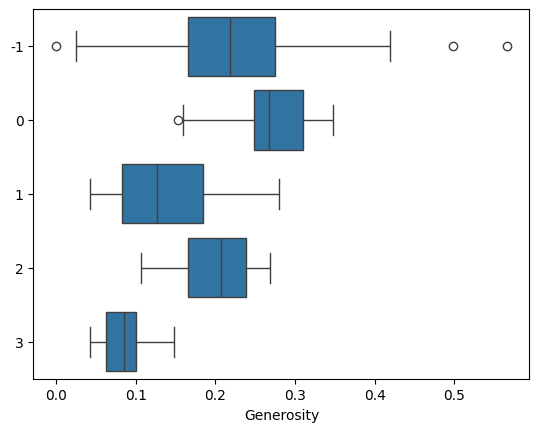

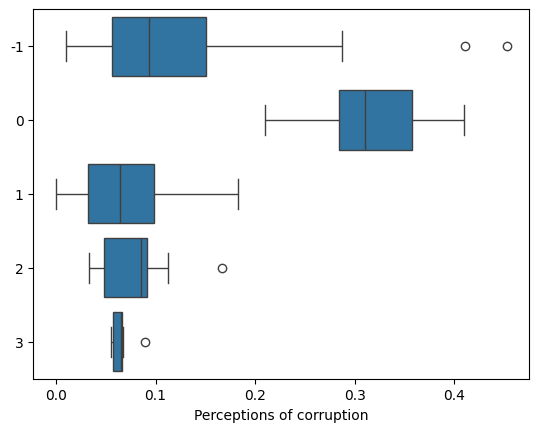

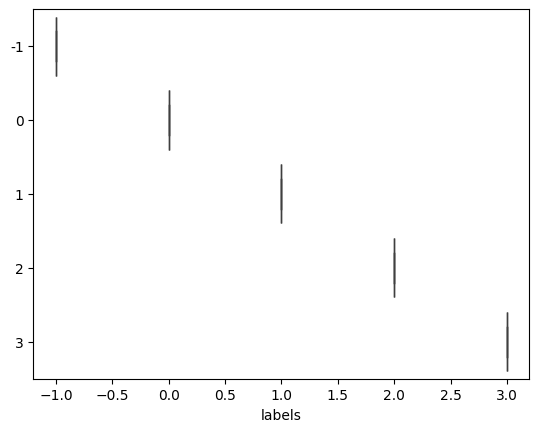

In [ ]:
for col in data.columns:
    sns.boxplot(data=data, x=col, y=labels, orient='h')
    plt.show();

То же в виде таблицы медиан признаков по кластерам. По ней удобно дать кластерам «имена».

In [ ]:
data.groupby('labels').median().T.round(2)

labels,-1,0,1,2,3
Score,4.67,7.28,5.94,4.42,4.51
GDP per capita,0.74,1.38,1.12,0.37,0.92
Social support,1.12,1.53,1.40,1.03,1.05
Healthy life expectancy,0.60,1.01,0.84,0.38,0.66
Freedom to make life choices,0.40,0.56,0.44,0.35,0.24
Generosity,0.22,0.27,0.13,0.21,0.09
Perceptions of corruption,0.09,0.31,0.06,0.08,0.06


Получились такие группы:
- **кластер 0** (10%) — самые счастливые страны (Score 7.28) с наибольшими ВВП, социальной поддержкой, продолжительностью жизни, свободой и доверием к власти (*Perceptions of corruption*);
- **кластер 1** (40%) — страны выше среднего (Score 5.94) с довольно высоким ВВП;
- **кластер 2** (12%) — бедные страны (ВВП 0.37, продолжительность жизни 0.38) с низким уровнем счастья;
- **кластер 3** (4%, 6 стран) — счастье тоже низкое, но ВВП средний; эту группу выделяют самые низкие свобода выбора (0.24) и щедрость (0.09);
- **шум** (−1, 34%) — страны «между» группами, они не попали ни в одну плотную область.

Страны из кластера 0 — Скандинавия, Западная Европа, Канада, Австралия и Новая Зеландия, то есть верхушка рейтинга счастья.

In [ ]:
country[data['labels'] == 0]

,Country or region
0,Finland
1,Denmark
2,Norway
4,Netherlands
5,Switzerland
6,Sweden
7,New Zealand
8,Canada
9,Austria
10,Australia


### 4.2 Иерархическая кластеризация

In [ ]:
# Удаляем метки DBSCAN, чтобы они не попали в признаки
data = data.drop(columns='labels')

Строим дендрограмму стран (`ward`). По длинным вертикальным отрезкам прикидываем, на сколько групп естественно делятся страны.

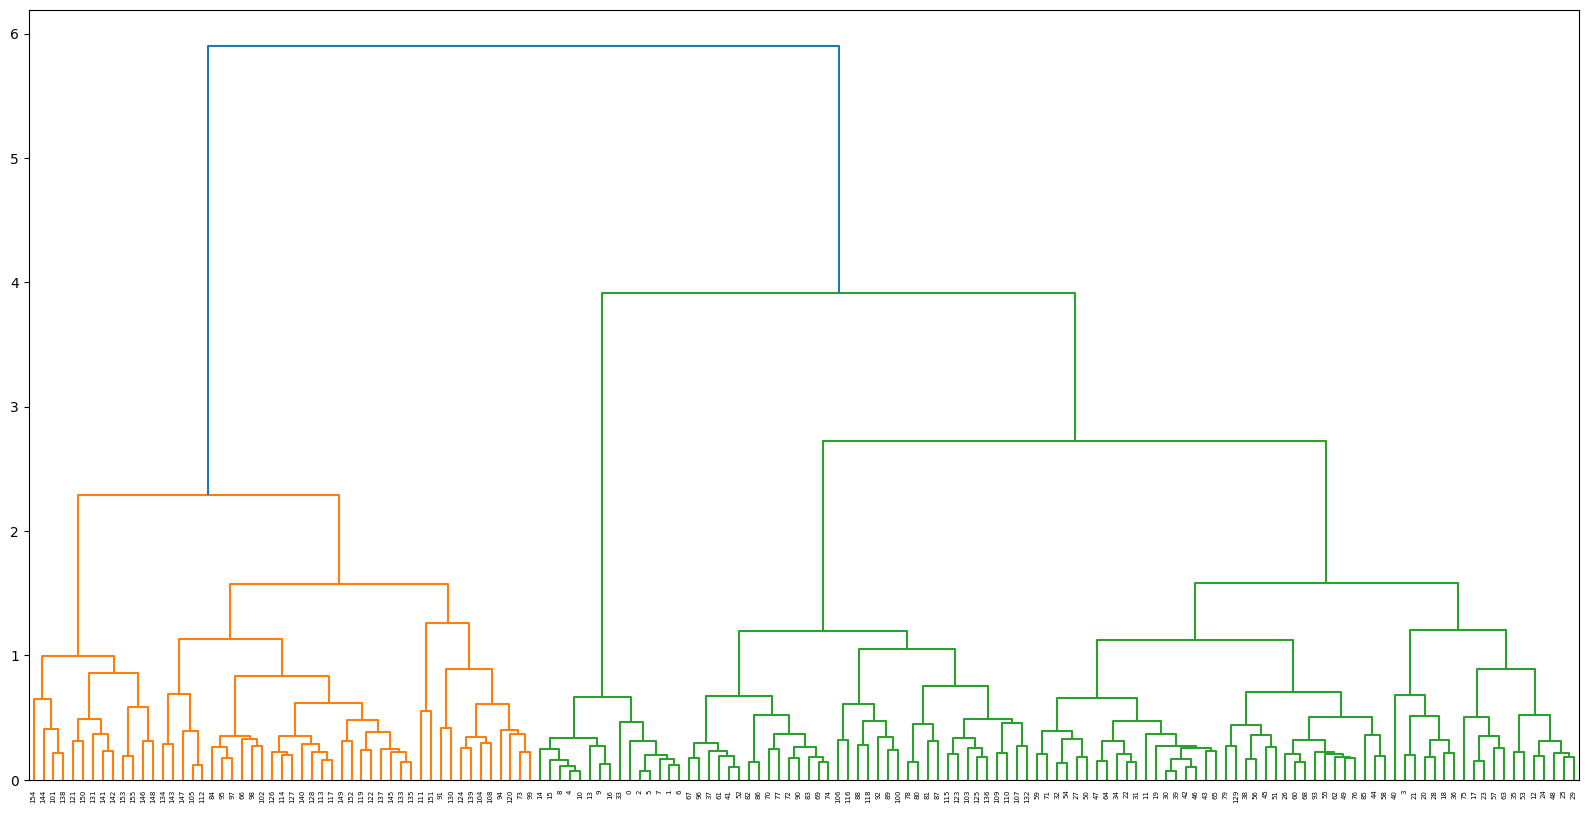

In [ ]:
plt.figure(figsize=(20,10))
linkage_ = linkage(X_scaled, method='ward')
dendrogram_ = dendrogram(linkage_)

На дендрограмме самый длинный вертикальный отрезок — у верхнего слияния (от ≈4 до ≈6): данные сначала делятся на 2 большие группы. Следующий заметный разрыв (от ≈2.7 до ≈4) отделяет ещё одну группу, поэтому разумно рассматривать 2 или 3 кластера.

Проверяем выбор числа кластеров по силуэту.

In [ ]:
silhouette = []
for i in tqdm(range(2,11)):
    agg = AgglomerativeClustering(n_clusters=i).fit(X_scaled)
    labels = agg.labels_
    score = silhouette_score(X_scaled, labels)
    silhouette.append(score)

100%|██████████| 9/9 [00:00<00:00, 174.74it/s]


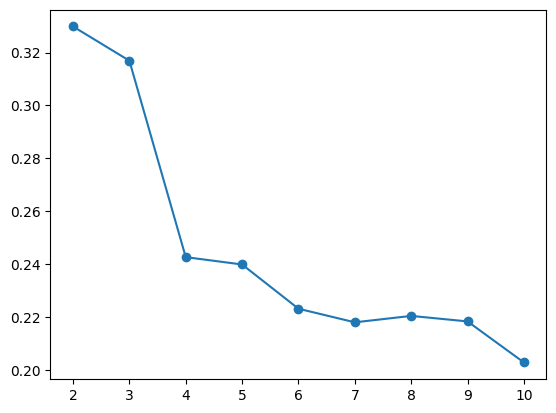

In [ ]:
plt.plot(range(2,11), silhouette, marker='o');

Силуэт максимален при 2 кластерах (≈0.33), но при 3 он почти такой же (≈0.32), а дальше резко падает. Вместе с дендрограммой это говорит в пользу 3 кластеров: они дают более подробное разбиение почти без потери качества.

Обучаем агломеративную кластеризацию с выбранным числом кластеров (3) и раскрашиваем картинку t-SNE. В отличие от DBSCAN, иерархическая кластеризация относит каждую страну к какому-то кластеру, шума здесь нет.

In [ ]:
agg = AgglomerativeClustering(n_clusters=3).fit(X_scaled)
labels = agg.labels_

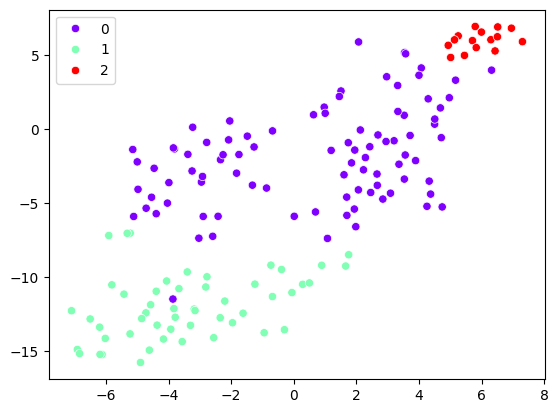

In [ ]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=labels, palette='rainbow');

Размеры кластеров и их интерпретация — так же, как для DBSCAN: ящики с усами по признакам и таблица медиан.

In [ ]:
data['labels'] = labels

In [ ]:
data['labels'].value_counts(normalize=True)

,proportion
labels,
0,0.576923
1,0.326923
2,0.096154


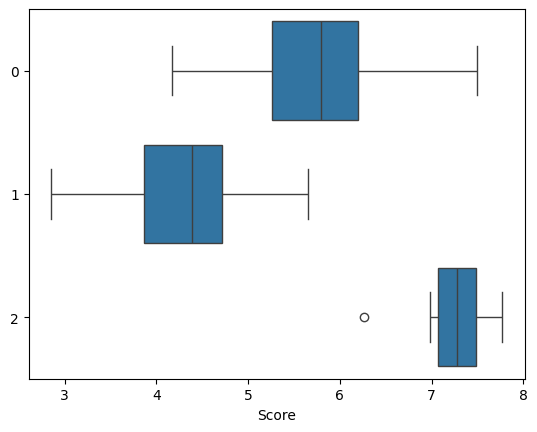

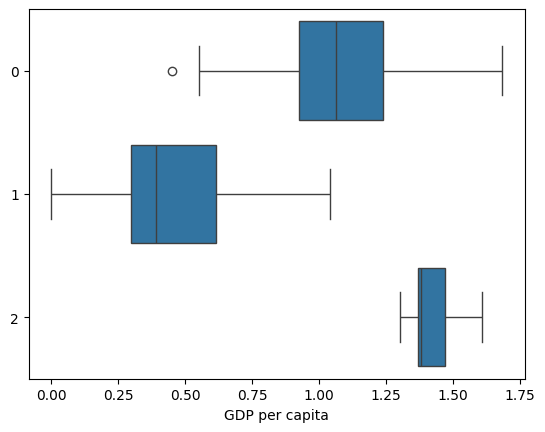

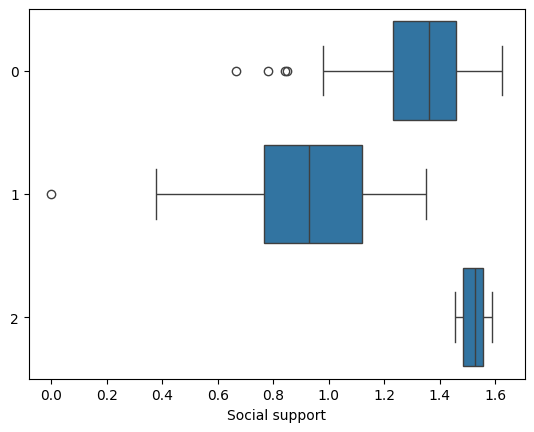

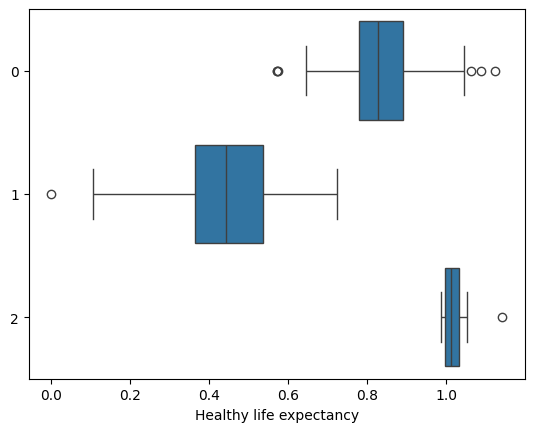

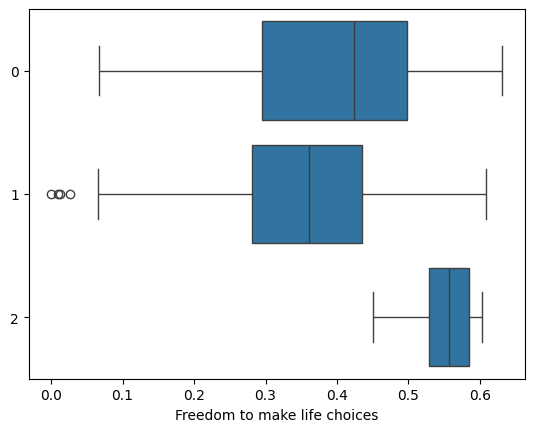

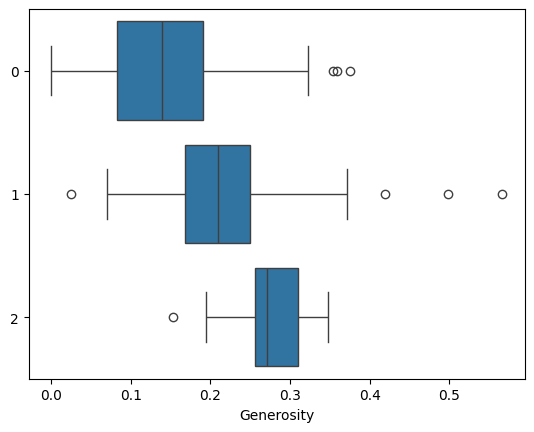

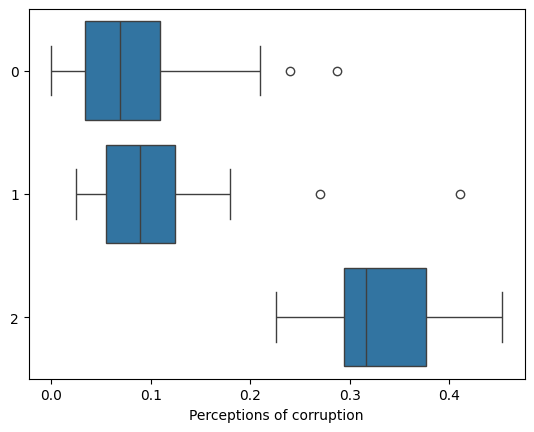

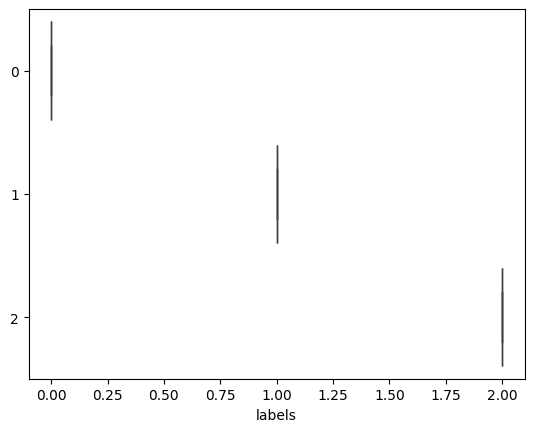

In [ ]:
for col in data.columns:
    sns.boxplot(data=data, x=col, y=labels, orient='h')
    plt.show();

In [ ]:
data.groupby('labels').median().T.round(2)

labels,0,1,2
Score,5.79,4.39,7.28
GDP per capita,1.06,0.39,1.38
Social support,1.36,0.93,1.53
Healthy life expectancy,0.83,0.44,1.01
Freedom to make life choices,0.42,0.36,0.56
Generosity,0.14,0.21,0.27
Perceptions of corruption,0.07,0.09,0.32


Кластеры упорядочены по уровню жизни:
- **кластер 2** (10% стран) — богатые и самые счастливые страны (медианный Score 7.28), по размеру (15 стран) и медианам он совпадает с кластером 0 у DBSCAN; кроме того, у них заметно выше показатель *Perceptions of corruption* — доверие к власти;
- **кластер 0** (58%) — «средний» уровень: Score 5.79, средние ВВП и продолжительность жизни;
- **кластер 1** (33%) — бедные страны с низкими ВВП (0.39) и продолжительностью жизни (0.44) и самым низким уровнем счастья (4.39).

Щедрость (*Generosity*) почти не связана с остальными признаками: у бедных стран она даже выше, чем у средних.

Страны из кластера 0 — самая большая, «средняя» группа: сюда попали и страны вроде Исландии и США, и Египет, Ирак, Шри-Ланка.

In [ ]:
country[data['labels'] == 0]

,Country or region
3,Iceland
11,Costa Rica
12,Israel
17,Belgium
18,United States
...,...
123,Tunisia
125,Iraq
129,Sri Lanka
132,Ukraine


**Итог.** Обе кластеризации выделили одинаковую по составу и медианам группу из 15 самых «счастливых» стран. Иерархическая разбила остальные на две понятные группы по уровню жизни; DBSCAN нашёл несколько более мелких групп, но треть стран счёл шумом. На этих данных нет явно разделённых групп разной плотности, поэтому для описания стран иерархическая кластеризация оказалась удобнее.